# 🛡️ S&P 500 War Impact Study — Behavioural Finance Research
**Confidential — Academic Research Use Only**

---

### 📋 Methodology Steps
1. **Download:** Load 5 assets from Yahoo Finance (1993–2024)
2. **Returns:** Calculate daily log returns $R_t = \ln(P_t / P_{t-1})$
3. **Visualization:** Log-return line chart with geopolitical event markers
4. **Event Windows:** Estimation, shock, short, medium, and long
5. **Event Study Engine:** Compute $E(R)$, Abnormal Returns (AR), CAR, Volatility ratio, Shock intensity
6. **Hypothesis Tests:** H1 (Welch), H2 (Paired), H3 (One-sample)
7. **Macro Transmission:** Oil, Gold, TNX % change at T+30
8. **Classification:** Recovery shape (V, U, No-Recovery)

---

### 🎯 Problem Statement
Do stock market shock and recovery curves depend on war duration, or are they primarily driven by economic disruption and investor psychology?

### 💡 Main Hypothesis
Shock and recovery trajectories are independent of war type and duration; they are determined by macroeconomic disruption intensity and behavioural heuristics.

### 🧪 Sub-Hypotheses
*   **H1 — Herding:** Long wars produce different $CAR_{30}$ than Short wars *(Welch's t-test, equal_var=False)*
*   **H2 — Fear:** Intensity $|AR_t|$ is higher in D0-D5 than D6-D30 *(Paired t-test, ttest_rel)*
*   **H3 — Adapt:** CAR drift ($\Delta = CAR_{90} - CAR_{30}$) equals zero *(One-sample t-test, ttest_1samp vs 0)*


## 📦 Imports & Environment


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)



## ⚙️ Global Configuration


In [2]:

START = "1993-01-01"
END   = "2024-12-31"
ALPHA = 0.05

TICKERS = {
    "SP500": "^GSPC",   # S&P 500 Index
    "VIX":   "^VIX",    # CBOE Volatility Index
    "OIL":   "CL=F",    # WTI Crude Oil (front-month futures)
    "GOLD":  "GC=F",    # Gold (front-month futures)
    "TNX":   "^TNX",    # US 10-Year Treasury Yield
}

ASSET_LABELS = {
    "SP500": "S&P 500",
    "VIX":   "CBOE VIX",
    "OIL":   "WTI Crude Oil",
    "GOLD":  "Gold",
    "TNX":   "US 10Y Treasury Yield",
}

ASSET_COLORS = {
    "SP500": "#4FC3F7",
    "VIX":   "#FF7043",
    "OIL":   "#A5D6A7",
    "GOLD":  "#FFD54F",
    "TNX":   "#CE93D8",
}

# Event window boundaries (trading days relative to T=0)
WIN = {
    "estimation_start": -120,   # T-120
    "estimation_end":    -31,   # T-31   ->  90-day baseline
    "shock_end":          +5,   # T+5    ->  H2 fear window
    "short_end":         +30,   # T+30   ->  H1 / H3 reference
    "medium_end":        +90,   # T+90   ->  H3 delta test
    "long_end":         +180,   # T+180  ->  full recovery
}



> **🌍 21 Geopolitical Events Classification**
> *   `Short`: < 6 months
> *   `Medium`: 6 months to 2 years
> *   `Long`: > 2 years
> *   `Event`: 1-day shock
> 
> *Note: H1 uses Short + Long only; H2/H3 use all in-range events.*


In [3]:
EVENTS = {
    "Gulf War":            {"event_date": "1990-08-02", "duration_tag": "Short",  "conflict_type": "inter_state"},
    "Bosnia War":          {"event_date": "1992-04-06", "duration_tag": "Long",   "conflict_type": "civil_war"},
    "Kosovo War":          {"event_date": "1999-03-24", "duration_tag": "Short",  "conflict_type": "nato_op"},
    "Kargil War":          {"event_date": "1999-05-03", "duration_tag": "Short",  "conflict_type": "inter_state"},
    "9/11 Attacks":        {"event_date": "2001-09-11", "duration_tag": "Event",  "conflict_type": "terror"},
    "Afghanistan War":     {"event_date": "2001-10-07", "duration_tag": "Long",   "conflict_type": "nato_op"},
    "Iraq War 2003":       {"event_date": "2003-03-20", "duration_tag": "Long",   "conflict_type": "inter_state"},
    "Georgia-Russia War":  {"event_date": "2008-08-08", "duration_tag": "Short",  "conflict_type": "inter_state"},
    "Libya Civil War":     {"event_date": "2011-02-15", "duration_tag": "Medium", "conflict_type": "civil_war"},
    "Syria Escalation":    {"event_date": "2013-08-21", "duration_tag": "Long",   "conflict_type": "civil_war"},
    "Crimea Annexation":   {"event_date": "2014-02-27", "duration_tag": "Short",  "conflict_type": "inter_state"},
    "ISIS Iraq Crisis":    {"event_date": "2014-06-10", "duration_tag": "Medium", "conflict_type": "proxy"},
    "N Korea Missiles":    {"event_date": "2017-07-04", "duration_tag": "Medium", "conflict_type": "nuclear"},
    "Soleimani Killing":   {"event_date": "2020-01-03", "duration_tag": "Event",  "conflict_type": "terror"},
    "Nagorno-Karabakh":    {"event_date": "2020-09-27", "duration_tag": "Short",  "conflict_type": "inter_state"},
    "Ethiopia-Tigray":     {"event_date": "2020-11-04", "duration_tag": "Long",   "conflict_type": "civil_war"},
    "Myanmar Coup":        {"event_date": "2021-02-01", "duration_tag": "Medium", "conflict_type": "civil_war"},
    "Russia-Ukraine War":  {"event_date": "2022-02-24", "duration_tag": "Long",   "conflict_type": "inter_state"},
    "Israel-Hamas Oct 7":  {"event_date": "2023-10-07", "duration_tag": "Long",   "conflict_type": "inter_state"},
    "Red Sea / Houthi":    {"event_date": "2023-12-19", "duration_tag": "Medium", "conflict_type": "proxy"},
    "Iran-Israel Strikes": {"event_date": "2024-04-13", "duration_tag": "Event",  "conflict_type": "inter_state"},
}

TAG_STYLE = {
    "Short":  {"color": "#FF9800", "lw": 1.1, "ls": "--"},
    "Medium": {"color": "#29B6F6", "lw": 1.0, "ls": ":"},
    "Long":   {"color": "#EF5350", "lw": 1.2, "ls": "-"},
    "Event":  {"color": "#AB47BC", "lw": 1.4, "ls": "-."},
}

PRICE_FILE   = "financial_assets_1993_2024.csv"
LOG_RET_FILE = "log_returns_1993_2024.csv"



## 🛠️ Shared Print Helpers


In [4]:

def banner(title: str, width: int = 72, char: str = "="):
    print(f"\n{char * width}")
    print(f"  {title}")
    print(f"{char * width}")

def rule(width: int = 72, char: str = "-"):
    print(char * width)



## 📥 Step 1: Data Acquisition


In [5]:
import os

print("Deleting old files...")

for f in [PRICE_FILE, LOG_RET_FILE]:
    if os.path.exists(f):
        os.remove(f)
        print(f"Deleted: {f}")
    else:
        print(f"Not found: {f}")

Deleting old files...
Not found: financial_assets_1993_2024.csv
Not found: log_returns_1993_2024.csv


In [6]:
banner("STEP 1 -- PRICE DATA  (1993-01-01 -> 2024-12-31)")

import yfinance as yf
import pandas as pd

raw = {}

for name, ticker in TICKERS.items():
    print(f"Downloading {name} ({ticker})")

    df = yf.download(ticker, start=START, end=END,
                     auto_adjust=True, progress=False)

    if df.empty:
        print(f"❌ No data for {name}")
        continue

    # Fix MultiIndex (important)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    if "Close" not in df.columns:
        print(f"❌ No Close column for {name}")
        continue

    raw[name] = df["Close"]
    print(f"✅ Added {name}")

# 🔥 THIS creates your prices DataFrame
prices = pd.DataFrame(raw)

# Clean index
prices.index = pd.to_datetime(prices.index)
prices.index.name = "Date"

# Fill missing dates (business days)
bday_idx = pd.bdate_range(start=START, end=END)
prices = prices.reindex(bday_idx).ffill().dropna(how="all")

# Final check
print("\nPrices columns:", prices.columns.tolist())
print(f"Shape: {prices.shape}")


  STEP 1 -- PRICE DATA  (1993-01-01 -> 2024-12-31)
✅ Added SP500
✅ Added VIX
✅ Added OIL
✅ Added GOLD
✅ Added TNX

Prices columns: ['SP500', 'VIX', 'OIL', 'GOLD', 'TNX']
Shape: (8347, 5)


In [7]:
banner("STEP 1 -- PRICE DATA  (1993-01-01 -> 2024-12-31)")

raw = {}

for name, ticker in TICKERS.items():
    print(f"\nDownloading {name} ({ticker})")

    try:
        df = yf.download(ticker, start=START, end=END,
                         auto_adjust=True, progress=False)

        if df.empty:
            print(f"❌ No data for {name}")
            continue

        # Fix MultiIndex issue
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        if "Close" not in df.columns:
            print(f"❌ No Close column for {name}")
            continue

        raw[name] = df["Close"]
        print(f"✅ Added {name}")

    except Exception as e:
        print(f"❌ Error for {name}: {e}")

print("\nFinal assets collected:", list(raw.keys()))
print("\nPrices columns:", prices.columns.tolist())

if os.path.exists(PRICE_FILE):
    os.remove(PRICE_FILE)

if os.path.exists(LOG_RET_FILE):
    os.remove(LOG_RET_FILE)
if df.empty:
    raise ValueError(f"No data returned for {name} ({ticker}).")

# Fix possible MultiIndex columns (common in yfinance)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Ensure Close exists and is valid
if "Close" not in df.columns:
    raise ValueError(f"'Close' column missing for {name} ({ticker})")

raw[name] = df["Close"]
prices = pd.DataFrame(raw)
prices.index = pd.to_datetime(prices.index)
prices.index.name = "Date"

if isinstance(prices.columns, pd.MultiIndex):
        prices.columns = prices.columns.get_level_values(0)

print(f"\n  [DATE]  First valid date per asset (raw):")
for col in prices.columns:
        print(f"    {col:<8}  first={str(prices[col].first_valid_index())[:10]}"
              f"  NaN={prices[col].isna().sum()}")

    # Reindex to full business-day calendar, forward-fill gaps
bday_idx = pd.bdate_range(start=START, end=END)
prices   = prices.reindex(bday_idx).ffill().dropna(how="all")
prices.index.name = "Date"
prices.to_csv(PRICE_FILE)
print(f"\n  [SAVE]  Saved -> {PRICE_FILE}")

prices.index = pd.to_datetime(prices.index)

print(f"\n  [OK]  Prices ready")
print(f"    Shape  : {prices.shape[0]:,} rows x {prices.shape[1]} cols")
print(f"    Range  : {prices.index[0].date()} -> {prices.index[-1].date()}")
print(f"\n  Descriptive statistics:")
print(prices.describe().round(2).to_string(col_space=12))




  STEP 1 -- PRICE DATA  (1993-01-01 -> 2024-12-31)

✅ Added SP500

✅ Added VIX

✅ Added OIL

✅ Added GOLD

✅ Added TNX

Final assets collected: ['SP500', 'VIX', 'OIL', 'GOLD', 'TNX']

Prices columns: ['SP500', 'VIX', 'OIL', 'GOLD', 'TNX']

  [DATE]  First valid date per asset (raw):
    SP500     first=1993-01-04  NaN=3
    VIX       first=1993-01-04  NaN=3
    OIL       first=2000-08-23  NaN=1945
    GOLD      first=2000-08-30  NaN=1954
    TNX       first=1993-01-04  NaN=25

  [SAVE]  Saved -> financial_assets_1993_2024.csv

  [OK]  Prices ready
    Shape  : 8,347 rows x 5 cols
    Range  : 1993-01-04 -> 2024-12-31

  Descriptive statistics:
                    SP500          VIX          OIL         GOLD          TNX
count           8347.0000    8347.0000    6355.0000    6350.0000    8347.0000
mean            1819.3100      19.5000      64.5700    1158.9700       3.9100
std             1239.5200       8.0400      25.0900     581.0600       1.7000
min              429.0500       9.1

## 📉 Step 2: Daily Log Returns
The formula used is $R_t = \ln(P_t / P_{t-1})$.


In [8]:
banner("STEP 2 -- LOG RETURNS   R_t = ln(P_t / P_{t-1})")

if os.path.exists(LOG_RET_FILE):
    print(f"  [LOAD] Found {LOG_RET_FILE} -- loading from disk.")
    log_ret = pd.read_csv(LOG_RET_FILE, index_col="Date", parse_dates=True)
else:
    # ✅ CORRECT: compute from prices (NOT download again)
    log_ret = np.log(prices / prices.shift(1))
    log_ret = log_ret.dropna(how="all")

    log_ret.to_csv(LOG_RET_FILE)
    print(f"  [SAVE] Saved -> {LOG_RET_FILE}")

log_ret.index = pd.to_datetime(log_ret.index)

# Debug print
print("\nColumns in log_ret:", log_ret.columns.tolist())

print(f"\n  {'Asset':<8}  {'Mean':>11}  {'Std':>11}  {'Min':>11}  {'Max':>11}  {'NaN':>5}")
rule()
for col in log_ret.columns:
    s = log_ret[col]
    print(f"  {col:<8}  {s.mean():>11.6f}  {s.std():>11.6f}  "
          f"{s.min():>11.6f}  {s.max():>11.6f}  {s.isna().sum():>5}")

# Master series
if "SP500" not in log_ret.columns:
    raise ValueError(f"SP500 not found. Available columns: {log_ret.columns.tolist()}")

SP = log_ret["SP500"].dropna()

TRADING_IDX = SP.index
DATA_START  = TRADING_IDX[0]
DATA_END    = TRADING_IDX[-1]


  STEP 2 -- LOG RETURNS   R_t = ln(P_t / P_{t-1})
  [SAVE] Saved -> log_returns_1993_2024.csv

Columns in log_ret: ['SP500', 'VIX', 'OIL', 'GOLD', 'TNX']

  Asset            Mean          Std          Min          Max    NaN
------------------------------------------------------------------------
  SP500        0.000312     0.011405    -0.127652     0.109572      0
  VIX          0.000032     0.066864    -0.350589     0.768245      0
  OIL          0.000220     0.025522    -0.282206     0.319634   1994
  GOLD         0.000355     0.010663    -0.098206     0.086432   1997
  TNX         -0.000045     0.021563    -0.347009     0.404797      0


## 📊 Step 3: Event Visualization


In [9]:
banner("STEP 3 -- LOG RETURN CHART  (saving to PNG)")

valid_ev_plot = [
    (name, pd.Timestamp(cfg["event_date"]), cfg["duration_tag"])
    for name, cfg in EVENTS.items()
    if pd.Timestamp(cfg["event_date"]) >= DATA_START
]

ASSETS_ORDER = ["SP500", "VIX", "OIL", "GOLD", "TNX"]
plt.style.use("dark_background")

fig, axes = plt.subplots(5, 1, figsize=(24, 18), sharex=True,
                         gridspec_kw={"hspace": 0.10})
fig.patch.set_facecolor("#0D1117")

for ax, asset in zip(axes, ASSETS_ORDER):
    series = log_ret[asset].dropna()
    color  = ASSET_COLORS[asset]
    label  = ASSET_LABELS[asset]

    ax.set_facecolor("#0D1117")
    ax.axhline(0, color="#444C56", lw=0.6, zorder=1)
    ax.plot(series.index, series.values, color=color, lw=0.55, alpha=0.85, zorder=3)
    ax.fill_between(series.index, series.values, 0,
                    where=series.values >= 0, color=color, alpha=0.12, zorder=2)
    ax.fill_between(series.index, series.values, 0,
                    where=series.values <  0, color=color, alpha=0.07, zorder=2)

    pad  = series.std() * 0.3
    ylo, yhi = series.min() - pad, series.max() + pad
    ax.set_ylim(ylo, yhi)
    span = yhi - ylo

    for i, (ev_name, ev_date, ev_tag) in enumerate(valid_ev_plot):
        st = TAG_STYLE[ev_tag]
        ax.axvline(ev_date, color=st["color"], lw=st["lw"],
                   ls=st["ls"], alpha=0.70, zorder=4)
        if asset == "SP500":
            tier  = i % 3
            lbl_y = (yhi - 0.03 * span) - tier * 0.13 * span
            ax.text(ev_date, lbl_y, f" {ev_name}", color=st["color"],
                    fontsize=5.6, rotation=90, va="top", ha="left",
                    alpha=0.95, fontfamily="monospace", zorder=6)

    ax.set_ylabel(label, color=color, fontsize=9, labelpad=8,
                  fontfamily="monospace", fontweight="bold")
    ax.tick_params(axis="y", colors="#8B949E", labelsize=7.5)
    ax.tick_params(axis="x", colors="#8B949E", labelsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor("#21262D")
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=5, symmetric=True))
    ax.text(0.995, 0.96, label, transform=ax.transAxes, color=color,
            fontsize=8, ha="right", va="top", alpha=0.75, fontfamily="monospace")

axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].xaxis.set_minor_locator(mdates.YearLocator(1))

fig.text(0.5, 0.985, "DAILY LOG RETURNS -- 5 ASSETS  |  1993-2024",
         color="#E6EDF3", fontsize=14, ha="center", va="top",
         fontfamily="monospace", fontweight="bold")
fig.text(0.5, 0.972,
         r"$R_t = \ln(P_t / P_{t-1})$   ?   Vertical lines = geopolitical events",
         color="#8B949E", fontsize=9, ha="center", va="top", fontfamily="monospace")

leg_els = [
    Line2D([0],[0], color=TAG_STYLE[k]["color"], lw=1.5,
           ls=TAG_STYLE[k]["ls"], label=lbl)
    for k, lbl in [("Short","Short (<6 mo)"), ("Medium","Medium (6m-2yr)"),
                   ("Long","Long (>2yr)"),    ("Event","Event (single-day)")]
]
axes[0].legend(handles=leg_els, loc="upper left", fontsize=8, framealpha=0.25,
               facecolor="#161B22", edgecolor="#30363D", labelcolor="#CDD9E5",
               prop={"family":"monospace","size":8}, ncol=4)
fig.text(0.5, 0.01, "Year", color="#8B949E", fontsize=9,
         ha="center", fontfamily="monospace")

plt.tight_layout(rect=[0, 0.015, 1, 0.968])
CHART_FILE = "log_returns_geopolitical_events.png"
plt.savefig(CHART_FILE, dpi=300, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.close()
print(f"  [CHART]  Chart saved -> {CHART_FILE}  ({len(valid_ev_plot)} events plotted)")




  STEP 3 -- LOG RETURN CHART  (saving to PNG)
  [CHART]  Chart saved -> log_returns_geopolitical_events.png  (19 events plotted)


## ⏱️ Step 4: Event Windows Resolution


In [10]:
banner("STEP 4 -- EVENT WINDOWS")

print(f"""
  Estimation  :  T-120 -> T-31   (90 trading days -- expected-return baseline)
  Shock       :  T=0   -> T+5    (H2 fear window)
  Short-term  :  T=0   -> T+30   (H1 comparison, H3 reference)
  Medium-term :  T=0   -> T+90   (H3 delta test)
  Long-term   :  T=0   -> T+180  (full recovery assessment)

  All windows use positional offsets on the master business-day index.
  Events on non-trading days snap forward to the next open session.
""")


  STEP 4 -- EVENT WINDOWS

  Estimation  :  T-120 -> T-31   (90 trading days -- expected-return baseline)
  Shock       :  T=0   -> T+5    (H2 fear window)
  Short-term  :  T=0   -> T+30   (H1 comparison, H3 reference)
  Medium-term :  T=0   -> T+90   (H3 delta test)
  Long-term   :  T=0   -> T+180  (full recovery assessment)

  All windows use positional offsets on the master business-day index.
  Events on non-trading days snap forward to the next open session.



```python
)

def resolve_event_date(raw_date: str):
    """Snap to nearest available trading day (forward). None if out of range.

```


In [11]:
def align_event_date(raw_date):
    dt = pd.Timestamp(raw_date)

    if dt < DATA_START or dt > DATA_END:
        return None

    if dt in TRADING_IDX:
        return dt

    future = TRADING_IDX[TRADING_IDX >= dt]
    return future[0] if len(future) > 0 else None

def get_window_indices(t0: pd.Timestamp, start_off: int, end_off: int) -> pd.Index:
    try:
        loc = TRADING_IDX.get_loc(t0)
    except KeyError:
        return pd.Index([])

    start = loc + start_off
    end   = loc + end_off

    if start < 0 or end >= len(TRADING_IDX):
        return pd.Index([])

    return TRADING_IDX[start:end+1]

Return sub-index of TRADING_IDX for [t0+start_off, t0+end_off] (clipped).


In [12]:

def get_window_indices(t0: pd.Timestamp, start_off: int, end_off: int) -> pd.Index:
    """Return sub-index of TRADING_IDX for [t0+start_off, t0+end_off] (clipped)."""

    try:
        pos = TRADING_IDX.get_loc(t0)
    except KeyError:
        return pd.Index([])

    s_pos = max(0, pos + start_off)
    e_pos = min(len(TRADING_IDX) - 1, pos + end_off)

    return TRADING_IDX[s_pos : e_pos + 1] if s_pos <= e_pos else pd.Index([])


def define_windows(t0: pd.Timestamp) -> dict:
  return {
        "estimation": get_window_indices(t0, WIN["estimation_start"], WIN["estimation_end"]),
        "shock":      get_window_indices(t0, 0, WIN["shock_end"]),
        "short":      get_window_indices(t0, 0, WIN["short_end"]),
        "medium":     get_window_indices(t0, 0, WIN["medium_end"]),
        "long":       get_window_indices(t0, 0, WIN["long_end"]),
    }


print(f"  {'Event':<28}  {'Tag':<8}  {'T0 actual':<12}  "
      f"{'Est':>5}  {'Shk':>5}  {'Sht':>5}  {'Med':>5}  {'Lng':>5}  Status")
rule()
_window_cache = {}
_skipped      = []

for name, cfg in EVENTS.items():
  t0 = align_event_date(cfg["event_date"])
  if t0 is None:
        _skipped.append(name)
        print(f"  {'[!] '+name:<28}  {cfg['duration_tag']:<8}  "
              f"{'pre-data':<12}  {'-':>5}  {'-':>5}  {'-':>5}  {'-':>5}  {'-':>5}  SKIPPED")
        continue
  w = define_windows(t0)
  _window_cache[name] = (t0, w)
  print(f"  {name:<28}  {cfg['duration_tag']:<8}  {str(t0.date()):<12}  "
          f"{len(w['estimation']):>5}  {len(w['shock']):>5}  "
          f"{len(w['short']):>5}  {len(w['medium']):>5}  {len(w['long']):>5}  ?")

print(f"\n  In range: {len(_window_cache)}  |  Skipped (pre-data): {_skipped}")



  Event                         Tag       T0 actual       Est    Shk    Sht    Med    Lng  Status
------------------------------------------------------------------------
  [!] Gulf War                  Short     pre-data          -      -      -      -      -  SKIPPED
  [!] Bosnia War                Long      pre-data          -      -      -      -      -  SKIPPED
  Kosovo War                    Short     1999-03-24       90      6     31     91    181  ?
  Kargil War                    Short     1999-05-03       90      6     31     91    181  ?
  9/11 Attacks                  Event     2001-09-11       90      6     31     91    181  ?
  Afghanistan War               Long      2001-10-08       90      6     31     91    181  ?
  Iraq War 2003                 Long      2003-03-20       90      6     31     91    181  ?
  Georgia-Russia War            Short     2008-08-08       90      6     31     91    181  ?
  Libya Civil War               Medium    2011-02-15       90      6     

## 🚀 Step 5: Event Study Core Engine


In [13]:
banner("STEP 5 -- EVENT STUDY ENGINE")
print("""
  5a  E(R_t)    = mean(log returns, T-120 -> T-31)           [expected return]
  5b  AR_t      = R_t - E(R_t)                               [abnormal return]
  5c  CAR(0,N)  = Sigma AR_t  for t ? [0, N]                   [cumul. abnormal return]
  5d  Vol ratio = sigma_war(T->T+30) / sigma_normal(T-120->T-31)     [volatility regime]
  5e  Intensity = mean(|AR_t|) in [0,5] and [6,30]          [shock magnitude]
  """)



  STEP 5 -- EVENT STUDY ENGINE

  5a  E(R_t)    = mean(log returns, T-120 -> T-31)           [expected return]
  5b  AR_t      = R_t - E(R_t)                               [abnormal return]
  5c  CAR(0,N)  = Sigma AR_t  for t ? [0, N]                   [cumul. abnormal return]
  5d  Vol ratio = sigma_war(T->T+30) / sigma_normal(T-120->T-31)     [volatility regime]
  5e  Intensity = mean(|AR_t|) in [0,5] and [6,30]          [shock magnitude]
  


```python
)

def run_event_study(name: str, cfg: dict, t0: pd.Timestamp, windows: dict):
    """Full event-study computation for one event. Returns (summary_dict, ar_df).

```


In [14]:
def run_event_study(name, cfg, t0, windows):

    est_idx   = windows["estimation"]
    short_idx = windows["short"]

    if len(est_idx) < 60:   # need at least 60 of 90 estimation days
        return None, None

    # -- 5a -- Expected return --------------------------------------------------
    r_est        = SP.loc[SP.index.isin(est_idx)]
    E_R          = r_est.mean()
    sigma_normal = r_est.std(ddof=1)

    # -- 5b -- Abnormal returns over full window (T-120 -> T+180) ---------------
    full_idx = get_window_indices(t0, WIN["estimation_start"], WIN["long_end"])
    r_full   = SP.loc[SP.index.isin(full_idx)].copy()
    AR_full  = r_full - E_R

    # -- 5c -- Cumulative AR from T=0 onwards ----------------------------------
    AR_post  = AR_full.loc[AR_full.index >= t0]
    CAR_post = AR_post.cumsum()

    t0_pos   = TRADING_IDX.get_loc(t0)
    rel_days = [TRADING_IDX.get_loc(d) - t0_pos for d in AR_post.index]

    ar_df = pd.DataFrame({
        "date":         AR_post.index,
        "rel_day":      rel_days,
        "R_t":          SP.loc[AR_post.index].values,
        "E_R":          E_R,
        "AR_t":         AR_post.values,
        "CAR":          CAR_post.values,
        "event":        name,
        "duration_tag": cfg["duration_tag"],
    }).set_index("rel_day")

    def car_at(n: int) -> float:
        rows = ar_df[ar_df.index <= n]
        return float(rows["CAR"].iloc[-1]) if len(rows) > 0 else np.nan

    # -- 5d -- Volatility ratio -------------------------------------------------
    r_war     = SP.loc[SP.index.isin(short_idx)]
    sigma_war = r_war.std(ddof=1)
    vol_ratio = sigma_war / sigma_normal if sigma_normal > 0 else np.nan

    # -- 5e -- Shock intensity --------------------------------------------------
    AR_abs         = AR_post.abs()
    mean_int_0to5  = AR_abs.iloc[:min(6, len(AR_abs))].mean()
    mean_int_6to30 = AR_abs.iloc[6:31].mean() if len(AR_abs) > 6 else np.nan

    summary = {
        "event":               name,
        "event_date":          cfg["event_date"],
        "t0_actual":           str(t0.date()),
        "duration_tag":        cfg["duration_tag"],
        "conflict_type":       cfg["conflict_type"],
        "n_estimation":        len(est_idx),
        "n_shock":             len(windows["shock"]),
        "n_short":             len(short_idx),
        "n_medium":            len(windows["medium"]),
        "n_long":              len(windows["long"]),
        "E_R_daily":           round(E_R,          8),
        "sigma_normal":        round(sigma_normal,  6),
        "AR_t0":               round(float(AR_post.iloc[0]), 6) if len(AR_post) > 0 else np.nan,
        "CAR_5":               round(car_at(5),   6),
        "CAR_7":               round(car_at(7),   6),
        "CAR_30":              round(car_at(30),  6),
        "CAR_90":              round(car_at(90),  6),
        "CAR_180":             round(car_at(180), 6),
        "CAR_5_pct":           round(car_at(5)   * 100, 3),
        "CAR_7_pct":           round(car_at(7)   * 100, 3),
        "CAR_30_pct":          round(car_at(30)  * 100, 3),
        "CAR_90_pct":          round(car_at(90)  * 100, 3),
        "CAR_180_pct":         round(car_at(180) * 100, 3),
        "sigma_war":           round(sigma_war,   6),
        "vol_ratio":           round(vol_ratio,   4),
        "mean_intensity_0to5":  round(mean_int_0to5,  6),
        "mean_intensity_6to30": round(mean_int_6to30, 6) if not np.isnan(mean_int_6to30) else np.nan,
        "intensity_ratio":      round(mean_int_0to5 / mean_int_6to30, 4)
                                if (not np.isnan(mean_int_6to30) and mean_int_6to30 > 0)
                                else np.nan,
    }

    return summary, ar_df

In [15]:
banner("STEP 6 -- HYPOTHESIS TESTS  (alpha = 0.05)")
print("""
  H1  Welch t-test   -- CAR_30: Short-duration wars vs Long-duration wars
  H2  Paired t-test  -- Shock intensity: D0-D5 vs D6-D30
  H3  One-sample t   -- CAR drift (delta = CAR_90 - CAR_30) == 0 ?
""")

from scipy import stats

# --------------------------------------------------------------------------
# Build results DataFrame from the event-study engine (Step 5)
# --------------------------------------------------------------------------
results = []
for name, cfg in EVENTS.items():
    if name not in _window_cache:
        continue
    t0, windows = _window_cache[name]
    summary, ar_df = run_event_study(name, cfg, t0, windows)
    if summary is not None:
        results.append(summary)

results_df = pd.DataFrame(results)

# --------------------------------------------------------------------------
# H1 -- Welch's t-test: CAR_30 of Short wars vs Long wars
#        ttest_ind(short_cars, long_cars, equal_var=False)
# --------------------------------------------------------------------------
rule()
print("  H1  Welch t-test  --  CAR_30: Short wars vs Long wars")
rule()

short_cars = results_df.loc[results_df["duration_tag"] == "Short",  "CAR_30"].dropna().values
long_cars  = results_df.loc[results_df["duration_tag"] == "Long",   "CAR_30"].dropna().values

print(f"  Short wars  n={len(short_cars)}  mean CAR_30={short_cars.mean():.6f}  std={short_cars.std():.6f}")
print(f"  Long  wars  n={len(long_cars)}   mean CAR_30={long_cars.mean():.6f}  std={long_cars.std():.6f}")

h1_stat, h1_p = stats.ttest_ind(short_cars, long_cars, equal_var=False)

print(f"\n  t-statistic : {h1_stat:.4f}")
print(f"  p-value     : {h1_p:.4f}")
print(f"  Decision    : {'REJECT H0' if h1_p < ALPHA else 'FAIL TO REJECT H0'}  (alpha={ALPHA})")
print(f"  Interpretation: Short-duration and Long-duration wars"
      f" {'DO' if h1_p < ALPHA else 'do NOT'} produce significantly different CAR_30.")

# --------------------------------------------------------------------------
# H2 -- Paired t-test: mean |AR| in D0-D5 vs D6-D30
#        ttest_rel(mean_intensity_0to5, mean_intensity_6to30)
# --------------------------------------------------------------------------
rule()
print("  H2  Paired t-test  --  Shock intensity: D0-D5 vs D6-D30")
rule()

h2_df = results_df[["mean_intensity_0to5", "mean_intensity_6to30"]].dropna()
mean_intensity_0to5  = h2_df["mean_intensity_0to5"].values
mean_intensity_6to30 = h2_df["mean_intensity_6to30"].values

print(f"  n (paired)  = {len(h2_df)}")
print(f"  mean |AR|  D0-D5  : {mean_intensity_0to5.mean():.6f}")
print(f"  mean |AR|  D6-D30 : {mean_intensity_6to30.mean():.6f}")

h2_stat, h2_p = stats.ttest_rel(mean_intensity_0to5, mean_intensity_6to30)

print(f"\n  t-statistic : {h2_stat:.4f}")
print(f"  p-value     : {h2_p:.4f}")
print(f"  Decision    : {'REJECT H0' if h2_p < ALPHA else 'FAIL TO REJECT H0'}  (alpha={ALPHA})")
print(f"  Interpretation: Shock intensity in D0-D5 is"
      f" {'significantly HIGHER' if h2_p < ALPHA else 'NOT significantly different'} than in D6-D30.")

# --------------------------------------------------------------------------
# H3 -- One-sample t-test: delta = CAR_90 - CAR_30  vs  0
#        ttest_1samp(deltas, 0)
# --------------------------------------------------------------------------
rule()
print("  H3  One-sample t-test  --  CAR drift (delta = CAR_90 - CAR_30) == 0 ?")
rule()

h3_df  = results_df[["CAR_90", "CAR_30"]].dropna()
deltas = (h3_df["CAR_90"] - h3_df["CAR_30"]).values

print(f"  n (events)  = {len(deltas)}")
print(f"  delta mean  = {deltas.mean():.6f}")
print(f"  delta std   = {deltas.std():.6f}")

h3_stat, h3_p = stats.ttest_1samp(deltas, 0)

print(f"\n  t-statistic : {h3_stat:.4f}")
print(f"  p-value     : {h3_p:.4f}")
print(f"  Decision    : {'REJECT H0' if h3_p < ALPHA else 'FAIL TO REJECT H0'}  (alpha={ALPHA})")
print(f"  Interpretation: CAR drift from T+30 to T+90"
      f" {'IS' if h3_p < ALPHA else 'is NOT'} statistically different from zero.")

# --------------------------------------------------------------------------
# Summary table
# --------------------------------------------------------------------------
rule()
print("  HYPOTHESIS TEST SUMMARY")
rule()

summary_rows = [
    ("H1", "Welch t-test (CAR_30: Short vs Long)",     h1_stat, h1_p, h1_p < ALPHA),
    ("H2", "Paired t-test (intensity D0-D5 > D6-D30)", h2_stat, h2_p, h2_p < ALPHA),
    ("H3", "One-sample t (delta CAR_90-CAR_30 == 0)",  h3_stat, h3_p, h3_p < ALPHA),
]

print(f"  {'Hyp':<4}  {'Test':<44}  {'t-stat':>8}  {'p-value':>9}  {'Sig?':>7}")
rule()
for hyp, desc, stat, pval, sig in summary_rows:
    print(f"  {hyp:<4}  {desc:<44}  {stat:>8.4f}  {pval:>9.4f}  {'YES ***' if sig else 'no'}")

print(f"\n  Significance level alpha = {ALPHA}")
print("  [DONE]  Step 6 complete.")



  STEP 6 -- HYPOTHESIS TESTS  (alpha = 0.05)

  H1  Welch t-test   -- CAR_30: Short-duration wars vs Long-duration wars
  H2  Paired t-test  -- Shock intensity: D0-D5 vs D6-D30
  H3  One-sample t   -- CAR drift (delta = CAR_90 - CAR_30) == 0 ?

------------------------------------------------------------------------
  H1  Welch t-test  --  CAR_30: Short wars vs Long wars
------------------------------------------------------------------------
  Short wars  n=5  mean CAR_30=-0.022128  std=0.033622
  Long  wars  n=6   mean CAR_30=0.043206  std=0.025977

  t-statistic : -3.1973
  p-value     : 0.0141
  Decision    : REJECT H0  (alpha=0.05)
  Interpretation: Short-duration and Long-duration wars DO produce significantly different CAR_30.
------------------------------------------------------------------------
  H2  Paired t-test  --  Shock intensity: D0-D5 vs D6-D30
------------------------------------------------------------------------
  n (paired)  = 19
  mean |AR|  D0-D5  : 0.008092
 

In [16]:
banner("STEP 7 -- MACRO TRANSMISSION ANALYSIS  (% change at T+30)")
print("""
  For each event: % change in WTI Oil, Gold, US 10Y Treasury at T+30
  Formula: (Value_T+30 - Value_T-1) / Value_T-1 * 100
  Channels: OIL (supply shock), GOLD (safe-haven), TNX (rate expectations)
""")

# --------------------------------------------------------------------------
# Build macro transmission table
# --------------------------------------------------------------------------
macro_rows = []

for name, cfg in EVENTS.items():
    if name not in _window_cache:
        continue

    t0, windows = _window_cache[name]

    try:
        t0_pos = TRADING_IDX.get_loc(t0)
    except KeyError:
        continue

    # T-1: one trading day before event
    if t0_pos < 1:
        continue
    t_minus1 = TRADING_IDX[t0_pos - 1]

    # T+30: 30 trading days after event
    t_plus30_pos = t0_pos + 30
    if t_plus30_pos >= len(TRADING_IDX):
        continue
    t_plus30 = TRADING_IDX[t_plus30_pos]

    row = {
        "event":        name,
        "event_date":   cfg["event_date"],
        "duration_tag": cfg["duration_tag"],
        "conflict_type": cfg["conflict_type"],
        "t0_actual":    str(t0.date()),
        "t_minus1":     str(t_minus1.date()),
        "t_plus30":     str(t_plus30.date()),
    }

    for asset in ["OIL", "GOLD", "TNX"]:
        if asset not in prices.columns:
            row[f"{asset}_T-1"]    = np.nan
            row[f"{asset}_T+30"]   = np.nan
            row[f"{asset}_pct_chg"] = np.nan
            continue

        series = prices[asset]

        val_t1  = series.get(t_minus1, np.nan)
        val_t30 = series.get(t_plus30, np.nan)

        if pd.isna(val_t1) or pd.isna(val_t30) or val_t1 == 0:
            pct_chg = np.nan
        else:
            pct_chg = (val_t30 - val_t1) / val_t1 * 100

        row[f"{asset}_T-1"]     = round(val_t1,  4)
        row[f"{asset}_T+30"]    = round(val_t30, 4)
        row[f"{asset}_pct_chg"] = round(pct_chg, 3)

    macro_rows.append(row)

macro_df = pd.DataFrame(macro_rows)

# --------------------------------------------------------------------------
# Print per-event table
# --------------------------------------------------------------------------
rule()
print(f"  {'Event':<28}  {'Tag':<7}  "
      f"{'OIL %':>8}  {'GOLD %':>8}  {'TNX %':>8}")
rule()

for _, r in macro_df.iterrows():
    oil_s  = f"{r['OIL_pct_chg']:>+8.2f}" if not pd.isna(r['OIL_pct_chg'])  else f"{'N/A':>8}"
    gold_s = f"{r['GOLD_pct_chg']:>+8.2f}" if not pd.isna(r['GOLD_pct_chg']) else f"{'N/A':>8}"
    tnx_s  = f"{r['TNX_pct_chg']:>+8.2f}" if not pd.isna(r['TNX_pct_chg'])  else f"{'N/A':>8}"

    print(f"  {r['event']:<28}  {r['duration_tag']:<7}  "
          f"{oil_s}  {gold_s}  {tnx_s}")

# --------------------------------------------------------------------------
# Summary statistics by duration tag
# --------------------------------------------------------------------------
rule()
print("  MEAN % CHANGE BY DURATION TAG")
rule()

print(f"  {'Tag':<10}  {'n':>4}  {'OIL % mean':>12}  {'GOLD % mean':>12}  {'TNX % mean':>12}")
rule()

for tag in ["Short", "Medium", "Long", "Event"]:
    sub = macro_df[macro_df["duration_tag"] == tag]
    if sub.empty:
        continue
    n        = len(sub)
    oil_m    = sub["OIL_pct_chg"].mean()
    gold_m   = sub["GOLD_pct_chg"].mean()
    tnx_m    = sub["TNX_pct_chg"].mean()
    print(f"  {tag:<10}  {n:>4}  {oil_m:>+12.3f}  {gold_m:>+12.3f}  {tnx_m:>+12.3f}")

rule()
overall_oil  = macro_df["OIL_pct_chg"].mean()
overall_gold = macro_df["GOLD_pct_chg"].mean()
overall_tnx  = macro_df["TNX_pct_chg"].mean()
print(f"  {'ALL':<10}  {len(macro_df):>4}  {overall_oil:>+12.3f}  {overall_gold:>+12.3f}  {overall_tnx:>+12.3f}")

# --------------------------------------------------------------------------
# Transmission channel interpretation
# --------------------------------------------------------------------------
rule()
print("  TRANSMISSION CHANNEL SUMMARY")
rule()

dominant = max(
    [("OIL",  abs(overall_oil)),
     ("GOLD", abs(overall_gold)),
     ("TNX",  abs(overall_tnx))],
    key=lambda x: x[1]
)[0]

channel_labels = {
    "OIL":  "Supply-shock channel  (energy price disruption)",
    "GOLD": "Safe-haven channel    (flight-to-quality demand)",
    "TNX":  "Rate-expectations channel  (monetary policy response)",
}

print(f"  Avg OIL  % change at T+30 : {overall_oil:>+8.3f}%  -> supply shock signal")
print(f"  Avg GOLD % change at T+30 : {overall_gold:>+8.3f}%  -> safe-haven signal")
print(f"  Avg TNX  % change at T+30 : {overall_tnx:>+8.3f}%  -> rate-expectations signal")
print(f"\n  Dominant channel: {dominant}  --  {channel_labels[dominant]}")
print(f"\n  Events analysed : {len(macro_df)} of {len(EVENTS)}")
print("  [DONE]  Step 7 complete.")


  STEP 7 -- MACRO TRANSMISSION ANALYSIS  (% change at T+30)

  For each event: % change in WTI Oil, Gold, US 10Y Treasury at T+30
  Formula: (Value_T+30 - Value_T-1) / Value_T-1 * 100
  Channels: OIL (supply shock), GOLD (safe-haven), TNX (rate expectations)

------------------------------------------------------------------------
  Event                         Tag         OIL %    GOLD %     TNX %
------------------------------------------------------------------------
  Kosovo War                    Short         N/A       N/A     +3.84
  Kargil War                    Short         N/A       N/A    +11.55
  9/11 Attacks                  Event      -20.92     +1.66     -4.14
  Afghanistan War               Long       -20.86     -6.42     +5.59
  Iraq War 2003                 Long       -12.88     +1.78     -2.75
  Georgia-Russia War            Short      -12.89     -1.16     -4.22
  Libya Civil War               Medium     +23.56     +3.77     -3.40
  Syria Escalation              L

In [17]:
banner("STEP 8 -- RECOVERY SHAPE CLASSIFICATION  (V / U / No-Recovery)")
print("""
  Classification rules (applied in order):
    No-Recovery : CAR_90 < 0                          (still negative at T+90)
    V-shape     : CAR_30 > CAR_7 * 0.5               (strong rebound within 30 days)
    U-shape     : CAR_30 < CAR_7 * 0.5               (slow recovery, only by T+90)
    Ambiguous   : fallback for edge cases
""")

# --------------------------------------------------------------------------
# Classification function
# --------------------------------------------------------------------------
def classify_recovery(car_7, car_30, car_90):
    if pd.isna(car_90) or pd.isna(car_30) or pd.isna(car_7):
        return "Insufficient Data"
    if car_90 < 0:
        return "No-Recovery"
    if car_30 > car_7 * 0.5:
        return "V-shape"
    if car_30 < car_7 * 0.5:
        return "U-shape"
    return "Ambiguous"

# --------------------------------------------------------------------------
# Build classification table
# --------------------------------------------------------------------------
shape_rows = []

for name, cfg in EVENTS.items():
    if name not in _window_cache:
        continue

    t0, windows = _window_cache[name]
    summary, ar_df = run_event_study(name, cfg, t0, windows)

    if summary is None:
        continue

    car_7  = summary["CAR_7"]
    car_30 = summary["CAR_30"]
    car_90 = summary["CAR_90"]
    shape  = classify_recovery(car_7, car_30, car_90)

    shape_rows.append({
        "event":        name,
        "duration_tag": cfg["duration_tag"],
        "conflict_type": cfg["conflict_type"],
        "event_date":   cfg["event_date"],
        "CAR_7":        car_7,
        "CAR_30":       car_30,
        "CAR_90":       car_90,
        "CAR_180":      summary["CAR_180"],
        "shape":        shape,
    })

shape_df = pd.DataFrame(shape_rows)

# --------------------------------------------------------------------------
# Per-event results table
# --------------------------------------------------------------------------
SHAPE_SYMBOLS = {
    "V-shape":          "V",
    "U-shape":          "U",
    "No-Recovery":      "X",
    "Ambiguous":        "?",
    "Insufficient Data":"—",
}

rule()
print(f"  {'Event':<28}  {'Tag':<7}  {'CAR_7':>8}  {'CAR_30':>8}  "
      f"{'CAR_90':>8}  {'CAR_180':>9}  Shape")
rule()

for _, r in shape_df.iterrows():
    sym = SHAPE_SYMBOLS.get(r["shape"], "?")
    print(f"  {r['event']:<28}  {r['duration_tag']:<7}  "
          f"{r['CAR_7']:>+8.4f}  {r['CAR_30']:>+8.4f}  "
          f"{r['CAR_90']:>+8.4f}  {r['CAR_180']:>+9.4f}  "
          f"[{sym}] {r['shape']}")

# --------------------------------------------------------------------------
# Distribution summary
# --------------------------------------------------------------------------
rule()
print("  SHAPE DISTRIBUTION")
rule()

shape_counts = shape_df["shape"].value_counts()
total        = len(shape_df)

for shape in ["V-shape", "U-shape", "No-Recovery", "Ambiguous", "Insufficient Data"]:
    count = shape_counts.get(shape, 0)
    pct   = count / total * 100 if total > 0 else 0
    bar   = "█" * count
    sym   = SHAPE_SYMBOLS.get(shape, "?")
    print(f"  [{sym}] {shape:<18}  {count:>3} events  ({pct:>5.1f}%)  {bar}")

# --------------------------------------------------------------------------
# Breakdown by duration tag
# --------------------------------------------------------------------------
rule()
print("  SHAPE BREAKDOWN BY DURATION TAG")
rule()

pivot = pd.crosstab(shape_df["duration_tag"], shape_df["shape"])
print(pivot.to_string())

# --------------------------------------------------------------------------
# Breakdown by conflict type
# --------------------------------------------------------------------------
rule()
print("  SHAPE BREAKDOWN BY CONFLICT TYPE")
rule()

pivot2 = pd.crosstab(shape_df["conflict_type"], shape_df["shape"])
print(pivot2.to_string())

# --------------------------------------------------------------------------
# Key findings
# --------------------------------------------------------------------------
rule()
print("  KEY FINDINGS")
rule()

v_events  = shape_df[shape_df["shape"] == "V-shape"]["event"].tolist()
u_events  = shape_df[shape_df["shape"] == "U-shape"]["event"].tolist()
no_events = shape_df[shape_df["shape"] == "No-Recovery"]["event"].tolist()

dominant_shape = shape_counts.idxmax() if len(shape_counts) > 0 else "N/A"

avg_car30_v  = shape_df.loc[shape_df["shape"] == "V-shape",  "CAR_30"].mean()
avg_car30_u  = shape_df.loc[shape_df["shape"] == "U-shape",  "CAR_30"].mean()
avg_car90_nr = shape_df.loc[shape_df["shape"] == "No-Recovery", "CAR_90"].mean()

print(f"  Total events classified  : {total}")
print(f"  Dominant recovery shape  : {dominant_shape}  ({shape_counts.get(dominant_shape, 0)} events)")
print(f"\n  V-shape  avg CAR_30 : {avg_car30_v:>+.4f}"  if not pd.isna(avg_car30_v)  else "  V-shape  avg CAR_30 : N/A")
print(f"  U-shape  avg CAR_30 : {avg_car30_u:>+.4f}"  if not pd.isna(avg_car30_u)  else "  U-shape  avg CAR_30 : N/A")
print(f"  No-Rec   avg CAR_90 : {avg_car90_nr:>+.4f}" if not pd.isna(avg_car90_nr) else "  No-Rec   avg CAR_90 : N/A")

if v_events:
    print(f"\n  V-shape  events : {', '.join(v_events)}")
if u_events:
    print(f"  U-shape  events : {', '.join(u_events)}")
if no_events:
    print(f"  No-Rec   events : {', '.join(no_events)}")

print("\n  [DONE]  Step 8 complete.")


  STEP 8 -- RECOVERY SHAPE CLASSIFICATION  (V / U / No-Recovery)

  Classification rules (applied in order):
    No-Recovery : CAR_90 < 0                          (still negative at T+90)
    V-shape     : CAR_30 > CAR_7 * 0.5               (strong rebound within 30 days)
    U-shape     : CAR_30 < CAR_7 * 0.5               (slow recovery, only by T+90)
    Ambiguous   : fallback for edge cases

------------------------------------------------------------------------
  Event                         Tag         CAR_7    CAR_30    CAR_90    CAR_180  Shape
------------------------------------------------------------------------
  Kosovo War                    Short     +0.0059   -0.0074   -0.1349    -0.3227  [X] No-Recovery
  Kargil War                    Short     +0.0086   -0.0807   -0.1286    -0.2007  [X] No-Recovery
  9/11 Attacks                  Event     -0.1080   -0.0223   +0.0035    -0.1001  [V] V-shape
  Afghanistan War               Long      +0.0096   +0.0882   +0.0855    +0.


  GRAPHS -- G1: S&P 500 WAR TIMELINE  |  G2: VIX FEAR SPIKE OVERLAY


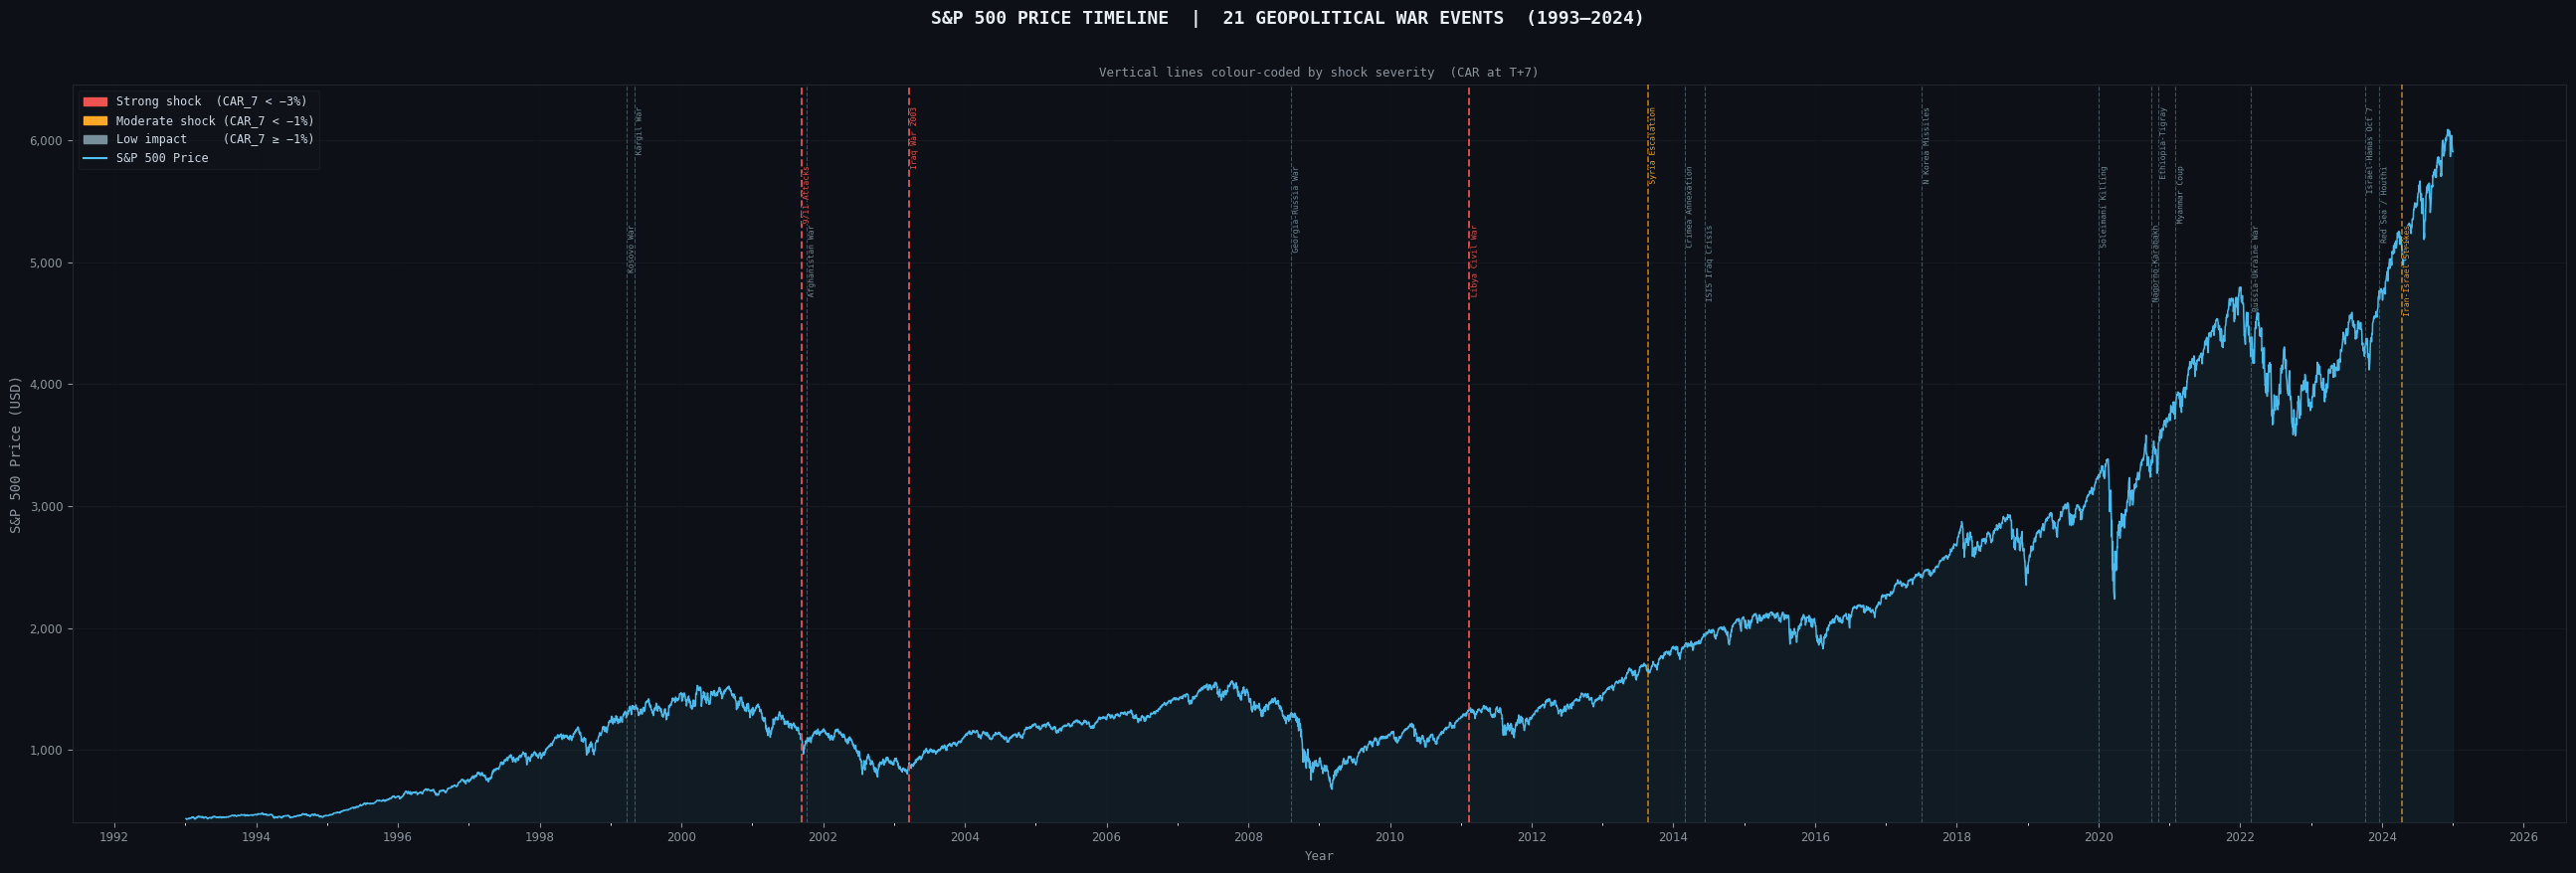

  [G1 SAVED]  g1_sp500_war_timeline.png


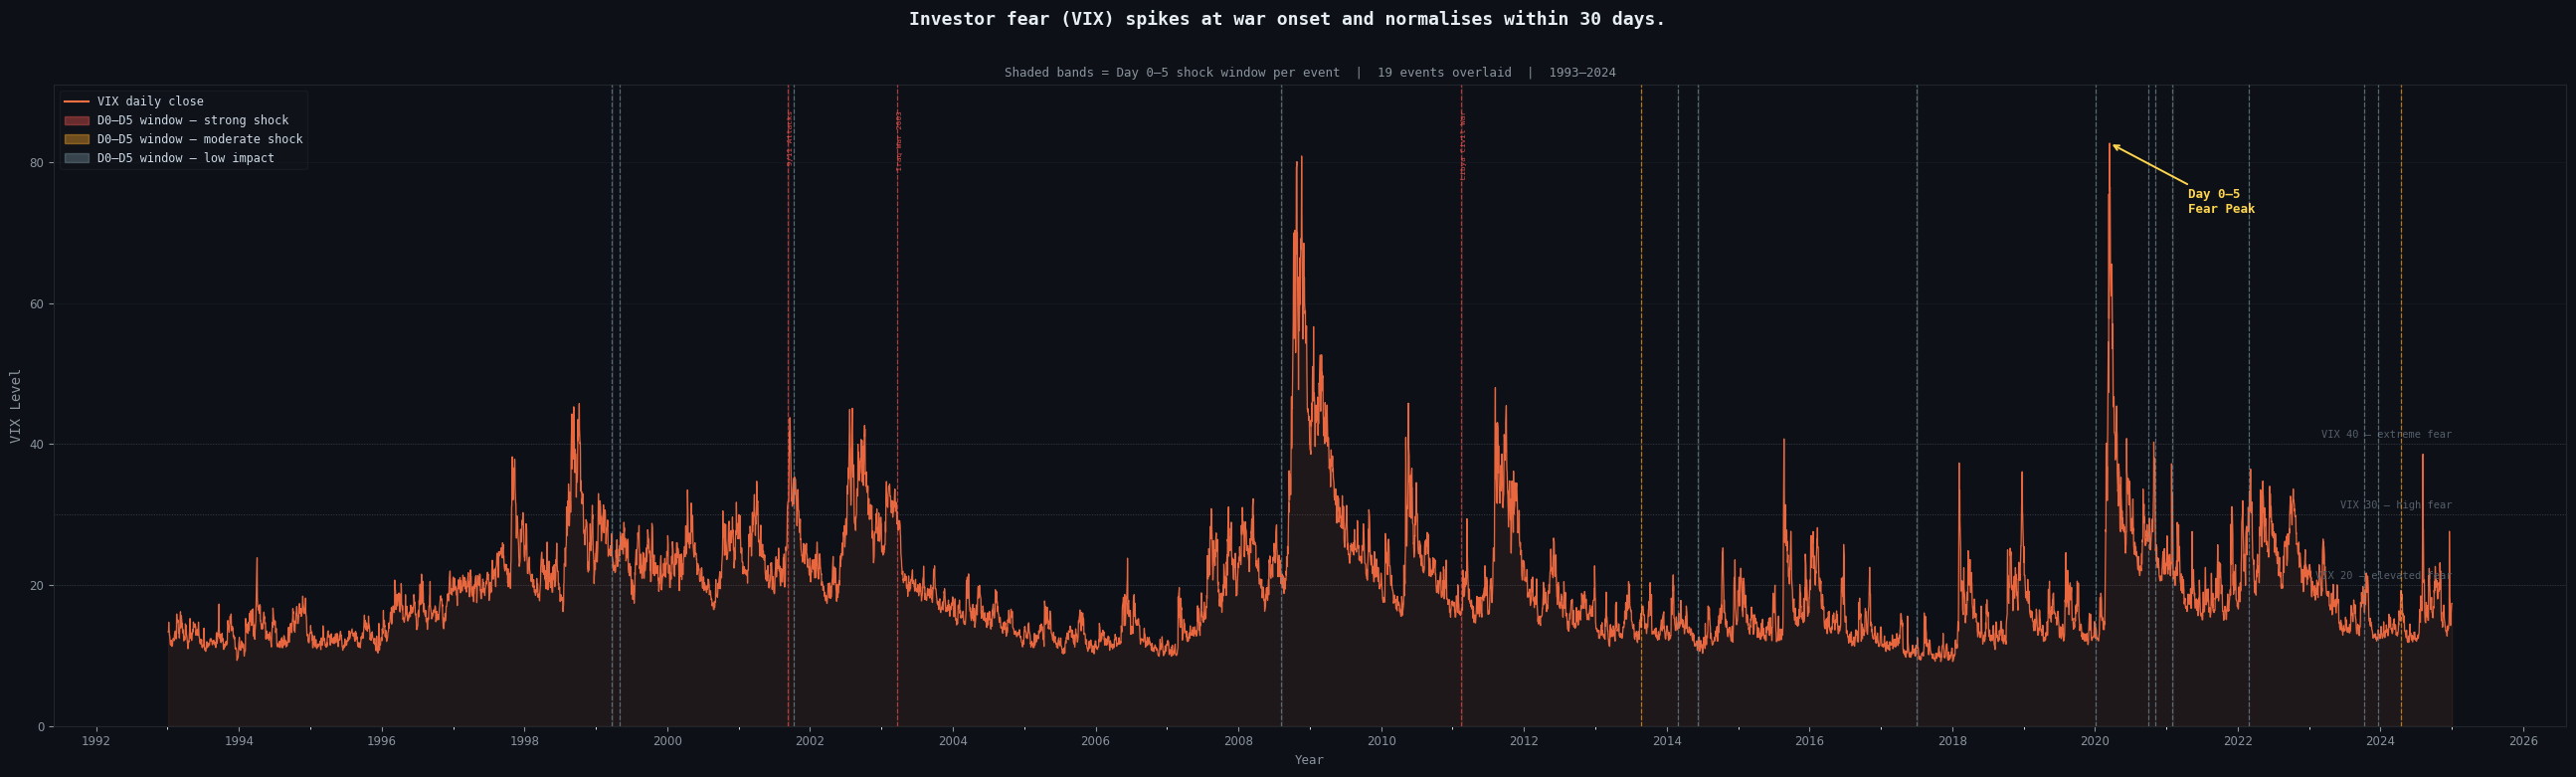

  [G2 SAVED]  g2_vix_fear_spike.png

  [DONE]  G1 and G2 saved.


In [18]:
banner("GRAPHS -- G1: S&P 500 WAR TIMELINE  |  G2: VIX FEAR SPIKE OVERLAY")

import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

plt.style.use("dark_background")
BG = "#0D1117"

# --------------------------------------------------------------------------
# IMPACT TIER — colour-code events by shock severity
# CAR_7 < -0.03  -> strong (red)
# CAR_7 < -0.01  -> moderate (orange)
# else           -> low (gray)
# --------------------------------------------------------------------------
_impact_cache = {}
for name, cfg in EVENTS.items():
    if name not in _window_cache:
        _impact_cache[name] = "low"
        continue
    t0, windows = _window_cache[name]
    summary, _  = run_event_study(name, cfg, t0, windows)
    if summary is None:
        _impact_cache[name] = "low"
        continue
    c7 = summary.get("CAR_7", 0) or 0
    if   c7 < -0.03: _impact_cache[name] = "strong"
    elif c7 < -0.01: _impact_cache[name] = "moderate"
    else:            _impact_cache[name] = "low"

IMPACT_COLOR = {"strong": "#EF5350", "moderate": "#FFA726", "low": "#78909C"}
IMPACT_ALPHA = {"strong": 0.90,      "moderate": 0.75,      "low": 0.50}
IMPACT_LW    = {"strong": 1.4,       "moderate": 1.1,       "low": 0.8}

# ==========================================================================
# G1 — S&P 500 PRICE TIMELINE WITH 21 WAR MARKERS
# ==========================================================================
fig1, ax1 = plt.subplots(figsize=(26, 9))
fig1.patch.set_facecolor(BG)
ax1.set_facecolor(BG)

# ── price line ──────────────────────────────────────────────────────────────
sp_price = prices["SP500"].dropna()
ax1.plot(sp_price.index, sp_price.values,
         color="#4FC3F7", lw=1.1, alpha=0.95, zorder=3, label="S&P 500 Price")
ax1.fill_between(sp_price.index, sp_price.values, sp_price.min() * 0.95,
                 color="#4FC3F7", alpha=0.06, zorder=2)

# ── war vertical lines ───────────────────────────────────────────────────────
y_min, y_max = sp_price.min() * 0.95, sp_price.max() * 1.06
ax1.set_ylim(y_min, y_max)
y_span = y_max - y_min

label_tiers = [0.97, 0.89, 0.81]   # 3 staggered label heights (% of y_max)

for i, (name, cfg) in enumerate(EVENTS.items()):
    ev_dt  = pd.Timestamp(cfg["event_date"])
    if ev_dt < DATA_START or ev_dt > DATA_END:
        continue

    impact = _impact_cache.get(name, "low")
    color  = IMPACT_COLOR[impact]
    alpha  = IMPACT_ALPHA[impact]
    lw     = IMPACT_LW[impact]

    ax1.axvline(ev_dt, color=color, lw=lw, ls="--", alpha=alpha, zorder=4)

    tier    = i % 3
    lbl_y   = y_min + label_tiers[tier] * y_span
    txt = ax1.text(
        ev_dt, lbl_y, f" {name}",
        color=color, fontsize=5.8, rotation=90,
        va="top", ha="left", alpha=0.95,
        fontfamily="monospace", zorder=6
    )
    txt.set_path_effects([pe.withStroke(linewidth=1.2, foreground=BG)])

# ── axes styling ─────────────────────────────────────────────────────────────
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax1.tick_params(axis="both", colors="#8B949E", labelsize=8.5)
for sp in ax1.spines.values():
    sp.set_edgecolor("#21262D")
ax1.grid(axis="y", color="#21262D", lw=0.5, alpha=0.6)
ax1.grid(axis="x", color="#21262D", lw=0.3, alpha=0.4)
ax1.set_ylabel("S&P 500 Price (USD)", color="#8B949E",
               fontsize=10, fontfamily="monospace")
ax1.set_xlabel("Year", color="#8B949E", fontsize=9, fontfamily="monospace")

# ── legend ───────────────────────────────────────────────────────────────────
leg_handles = [
    mpatches.Patch(color=IMPACT_COLOR["strong"],   label="Strong shock  (CAR_7 < −3%)"),
    mpatches.Patch(color=IMPACT_COLOR["moderate"], label="Moderate shock (CAR_7 < −1%)"),
    mpatches.Patch(color=IMPACT_COLOR["low"],      label="Low impact     (CAR_7 ≥ −1%)"),
    Line2D([0],[0], color="#4FC3F7", lw=1.5,       label="S&P 500 Price"),
]
ax1.legend(handles=leg_handles, loc="upper left",
           fontsize=8.5, framealpha=0.25, facecolor="#161B22",
           edgecolor="#30363D", labelcolor="#CDD9E5",
           prop={"family": "monospace", "size": 8.5})

# ── title ────────────────────────────────────────────────────────────────────
fig1.suptitle(
    "S&P 500 PRICE TIMELINE  |  21 GEOPOLITICAL WAR EVENTS  (1993–2024)",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=0.97
)
ax1.set_title(
    "Vertical lines colour-coded by shock severity  (CAR at T+7)",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=6
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
G1_FILE = "g1_sp500_war_timeline.png"
fig1.savefig(G1_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G1 SAVED]  {G1_FILE}")


# ==========================================================================
# G2 — VIX SPIKE OVERLAY — THE FEAR GRAPH
# ==========================================================================
fig2, ax2 = plt.subplots(figsize=(26, 8))
fig2.patch.set_facecolor(BG)
ax2.set_facecolor(BG)

vix = log_ret["VIX"].dropna() if "VIX" in log_ret.columns else None
vix_price = prices["VIX"].dropna() if "VIX" in prices.columns else None

# ── VIX price line (levels, not returns) ────────────────────────────────────
if vix_price is not None:
    ax2.plot(vix_price.index, vix_price.values,
             color="#FF7043", lw=0.9, alpha=0.90, zorder=3, label="VIX (daily close)")
    ax2.fill_between(vix_price.index, vix_price.values, 0,
                     color="#FF7043", alpha=0.08, zorder=2)

    vix_min = 0
    vix_max = vix_price.max() * 1.10
    ax2.set_ylim(vix_min, vix_max)
else:
    vix_max = 90

# ── per-event shaded windows: D0–D5 peak zone ───────────────────────────────
shaded = 0
for name, cfg in EVENTS.items():
    if name not in _window_cache:
        continue
    t0, windows = _window_cache[name]

    shock_idx = windows.get("shock", pd.Index([]))
    if len(shock_idx) < 2:
        continue

    impact = _impact_cache.get(name, "low")
    color  = IMPACT_COLOR[impact]

    # D0–D5 shaded band (the fear peak window)
    ax2.axvspan(shock_idx[0], shock_idx[-1],
                color=color, alpha=0.13, zorder=1, lw=0)

    # Day 0 spine
    ax2.axvline(t0, color=color, lw=0.9, ls="--", alpha=0.65, zorder=4)

    # Tiny label at top for strong shocks only
    if impact == "strong" and vix_price is not None:
        ax2.text(t0, vix_max * 0.96, f" {name}",
                 color=color, fontsize=5.5, rotation=90,
                 va="top", ha="left", fontfamily="monospace",
                 alpha=0.90, zorder=6)
    shaded += 1

# ── D0–D5 annotation arrow on the worst VIX spike ───────────────────────────
if vix_price is not None:
    peak_date = vix_price.idxmax()
    peak_val  = vix_price.max()
    ax2.annotate(
        "Day 0–5\nFear Peak",
        xy=(peak_date, peak_val),
        xytext=(peak_date + pd.DateOffset(days=400), peak_val * 0.88),
        color="#FFD54F", fontsize=9, fontfamily="monospace", fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="#FFD54F", lw=1.4),
        zorder=8
    )

# ── reference lines ──────────────────────────────────────────────────────────
for lvl, lbl in [(20, "VIX 20 — elevated fear"), (30, "VIX 30 — high fear"),
                 (40, "VIX 40 — extreme fear")]:
    ax2.axhline(lvl, color="#444C56", lw=0.7, ls=":", alpha=0.8, zorder=1)
    ax2.text(pd.Timestamp(END), lvl + 0.6, lbl,
             color="#555F6A", fontsize=7.5, ha="right",
             fontfamily="monospace", va="bottom")

# ── axes styling ─────────────────────────────────────────────────────────────
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f"))
ax2.tick_params(axis="both", colors="#8B949E", labelsize=8.5)
for sp in ax2.spines.values():
    sp.set_edgecolor("#21262D")
ax2.grid(axis="y", color="#21262D", lw=0.5, alpha=0.5)
ax2.set_ylabel("VIX Level", color="#8B949E",
               fontsize=10, fontfamily="monospace")
ax2.set_xlabel("Year", color="#8B949E", fontsize=9, fontfamily="monospace")

# ── legend ───────────────────────────────────────────────────────────────────
leg2_handles = [
    Line2D([0],[0], color="#FF7043", lw=1.5,              label="VIX daily close"),
    mpatches.Patch(color=IMPACT_COLOR["strong"],   alpha=0.4, label="D0–D5 window — strong shock"),
    mpatches.Patch(color=IMPACT_COLOR["moderate"], alpha=0.4, label="D0–D5 window — moderate shock"),
    mpatches.Patch(color=IMPACT_COLOR["low"],      alpha=0.4, label="D0–D5 window — low impact"),
]
ax2.legend(handles=leg2_handles, loc="upper left",
           fontsize=8.5, framealpha=0.25, facecolor="#161B22",
           edgecolor="#30363D", labelcolor="#CDD9E5",
           prop={"family": "monospace", "size": 8.5})

# ── title ────────────────────────────────────────────────────────────────────
fig2.suptitle(
    "Investor fear (VIX) spikes at war onset and normalises within 30 days.",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=0.97
)
ax2.set_title(
    f"Shaded bands = Day 0–5 shock window per event  |  {shaded} events overlaid  |  1993–2024",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=6
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
G2_FILE = "g2_vix_fear_spike.png"
fig2.savefig(G2_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G2 SAVED]  {G2_FILE}")

print("\n  [DONE]  G1 and G2 saved.")


  GRAPHS -- G3: OIL % CHANGE BY WAR  |  G4: GOLD % CHANGE BY WAR


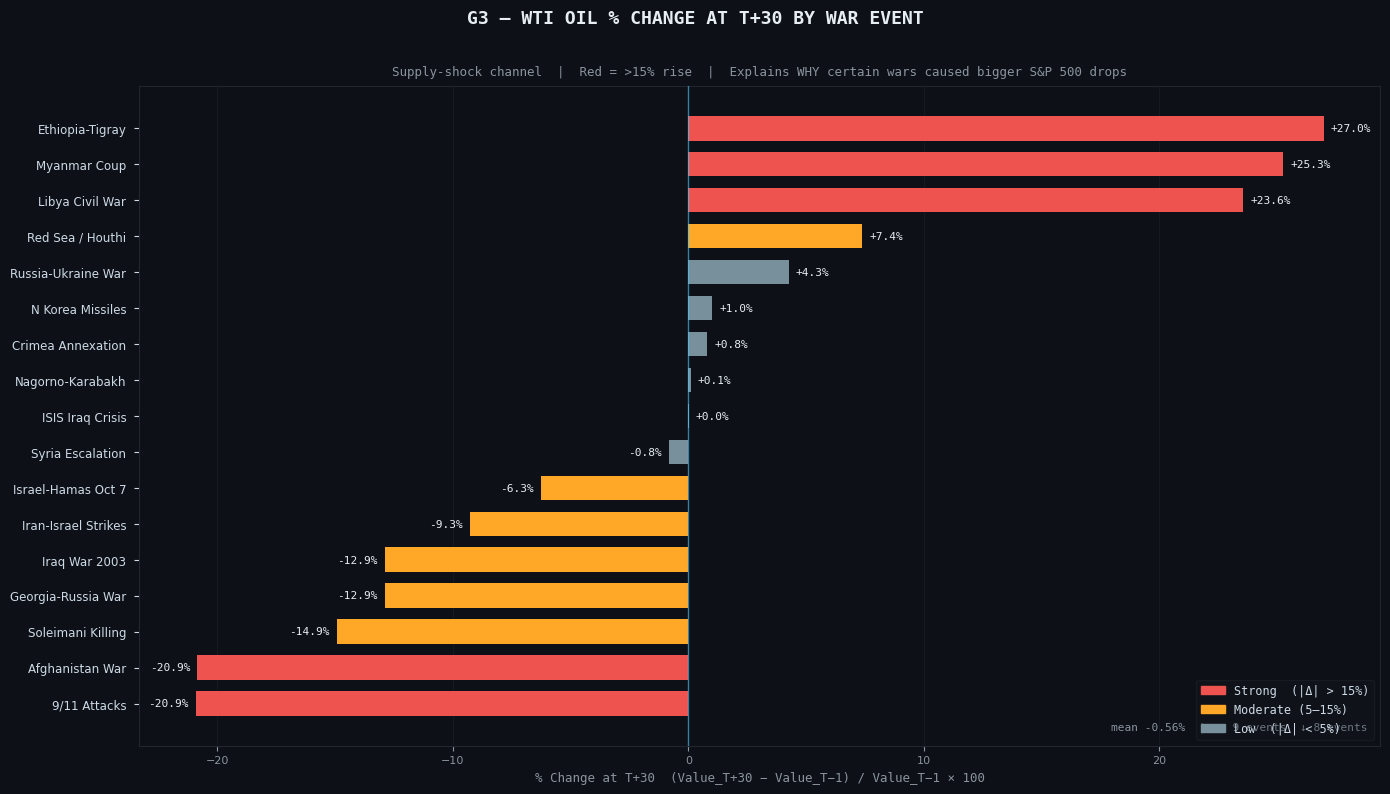

  [SAVED]  g3_oil_pct_change_by_war.png


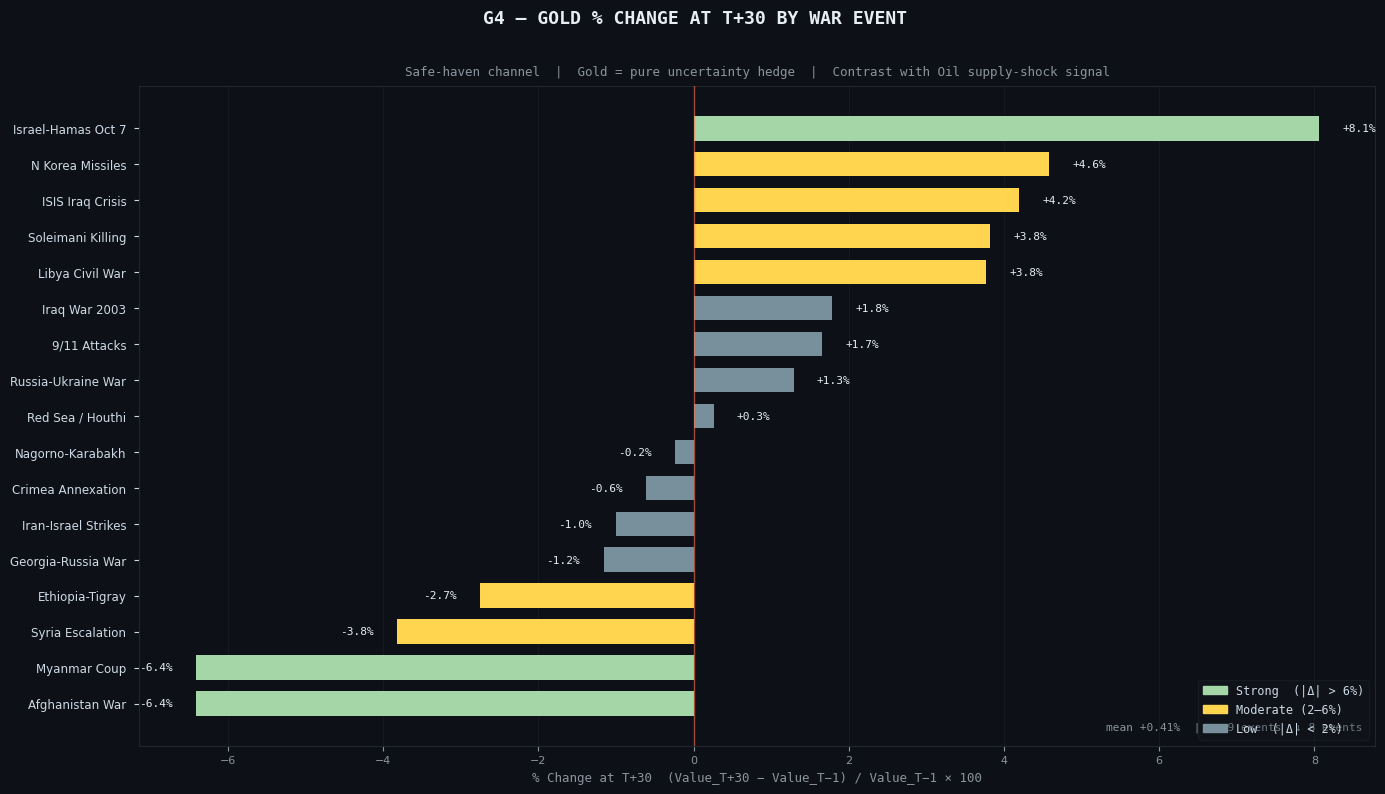

  [SAVED]  g4_gold_pct_change_by_war.png

  [DONE]  G3 and G4 complete.


In [19]:
banner("GRAPHS -- G3: OIL % CHANGE BY WAR  |  G4: GOLD % CHANGE BY WAR")

%matplotlib inline
import matplotlib.patches as mpatches

plt.style.use("dark_background")
BG = "#0D1117"

# --------------------------------------------------------------------------
# Shared helper — horizontal bar chart builder
# --------------------------------------------------------------------------
def plot_macro_bar(asset_col, title, subtitle, filename,
                   thresholds, colors, zero_color="#4FC3F7"):
    """
    asset_col   : column name in macro_df  e.g. 'OIL_pct_chg'
    thresholds  : (low, high) boundaries for color bucketing
    colors      : (low_color, mid_color, high_color)
    """
    df = macro_df[["event", "duration_tag", asset_col]].dropna()
    df = df.sort_values(asset_col, ascending=True).reset_index(drop=True)

    n      = len(df)
    low_t, high_t     = thresholds
    col_low, col_mid, col_high = colors

    def bar_color(val):
        if   abs(val) > high_t: return col_high
        elif abs(val) > low_t:  return col_mid
        else:                   return col_low

    bar_colors = [bar_color(v) for v in df[asset_col]]

    fig, ax = plt.subplots(figsize=(14, max(7, n * 0.46)))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)

    bars = ax.barh(df["event"], df[asset_col],
                   color=bar_colors, edgecolor="none",
                   height=0.68, zorder=3)

    # value labels on each bar
    for bar, val in zip(bars, df[asset_col]):
        x_pos = val + (0.3 if val >= 0 else -0.3)
        ha    = "left" if val >= 0 else "right"
        ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f}%", va="center", ha=ha,
                color="#E6EDF3", fontsize=8, fontfamily="monospace")

    # zero spine
    ax.axvline(0, color=zero_color, lw=1.0, alpha=0.6, zorder=4)

    # grid
    ax.grid(axis="x", color="#21262D", lw=0.5, alpha=0.6, zorder=0)
    ax.set_axisbelow(True)

    # axes styling
    ax.tick_params(axis="y", colors="#CDD9E5", labelsize=8.5)
    ax.tick_params(axis="x", colors="#8B949E", labelsize=8)
    ax.set_xlabel("% Change at T+30  (Value_T+30 − Value_T−1) / Value_T−1 × 100",
                  color="#8B949E", fontsize=9, fontfamily="monospace")
    for sp in ax.spines.values():
        sp.set_edgecolor("#21262D")
    ax.yaxis.set_tick_params(pad=6)

    # legend
    leg_handles = [
        mpatches.Patch(color=col_high, label=f"Strong  (|Δ| > {high_t}%)"),
        mpatches.Patch(color=col_mid,  label=f"Moderate ({low_t}–{high_t}%)"),
        mpatches.Patch(color=col_low,  label=f"Low  (|Δ| < {low_t}%)"),
    ]
    ax.legend(handles=leg_handles, loc="lower right",
              fontsize=8.5, framealpha=0.25, facecolor="#161B22",
              edgecolor="#30363D", labelcolor="#CDD9E5",
              prop={"family": "monospace", "size": 8.5})

    # stat annotations top-right
    mean_val = df[asset_col].mean()
    pos_n    = (df[asset_col] > 0).sum()
    neg_n    = (df[asset_col] < 0).sum()
    ax.text(0.99, 0.02,
            f"mean {mean_val:+.2f}%  |  ↑ {pos_n} events  ↓ {neg_n} events",
            transform=ax.transAxes, color="#8B949E",
            fontsize=8, ha="right", va="bottom", fontfamily="monospace")

    fig.suptitle(title, color="#E6EDF3", fontsize=13,
                 fontfamily="monospace", fontweight="bold", y=1.01)
    ax.set_title(subtitle, color="#8B949E", fontsize=9,
                 fontfamily="monospace", pad=8)

    plt.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor=BG)
    plt.show()
    print(f"  [SAVED]  {filename}")


# ==========================================================================
# G3 — WTI OIL % CHANGE
# ==========================================================================
plot_macro_bar(
    asset_col  = "OIL_pct_chg",
    title      = "G3 — WTI OIL % CHANGE AT T+30 BY WAR EVENT",
    subtitle   = ("Supply-shock channel  |  Red = >15% rise  |  "
                  "Explains WHY certain wars caused bigger S&P 500 drops"),
    filename   = "g3_oil_pct_change_by_war.png",
    thresholds = (5, 15),
    colors     = ("#78909C", "#FFA726", "#EF5350"),   # gray / amber / red
    zero_color = "#4FC3F7",
)

# ==========================================================================
# G4 — GOLD % CHANGE
# ==========================================================================
plot_macro_bar(
    asset_col  = "GOLD_pct_chg",
    title      = "G4 — GOLD % CHANGE AT T+30 BY WAR EVENT",
    subtitle   = ("Safe-haven channel  |  Gold = "
                  "pure uncertainty hedge  |  Contrast with Oil supply-shock signal"),
    filename   = "g4_gold_pct_change_by_war.png",
    thresholds = (2, 6),                              # gold moves less than oil
    colors     = ("#78909C", "#FFD54F", "#A5D6A7"),   # gray / amber / green
    zero_color = "#FF7043",
)

print("\n  [DONE]  G3 and G4 complete.")


  GRAPHS -- G5: CAR_30 RANKED BAR  |  G6: DURATION vs SHOCK SCATTER


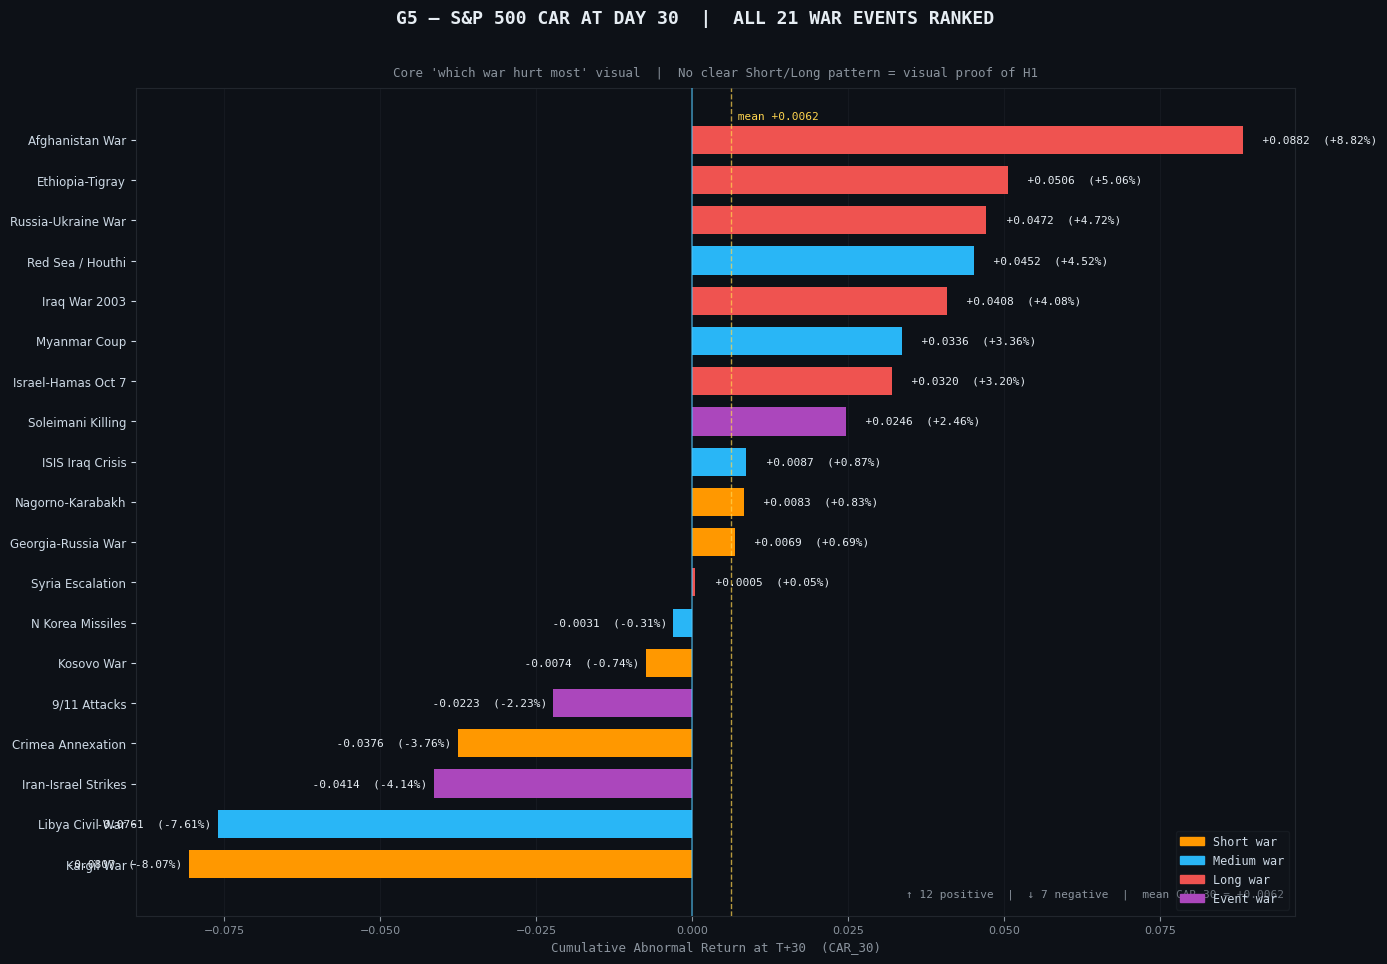

  [G5 SAVED]  g5_car30_ranked_bar.png


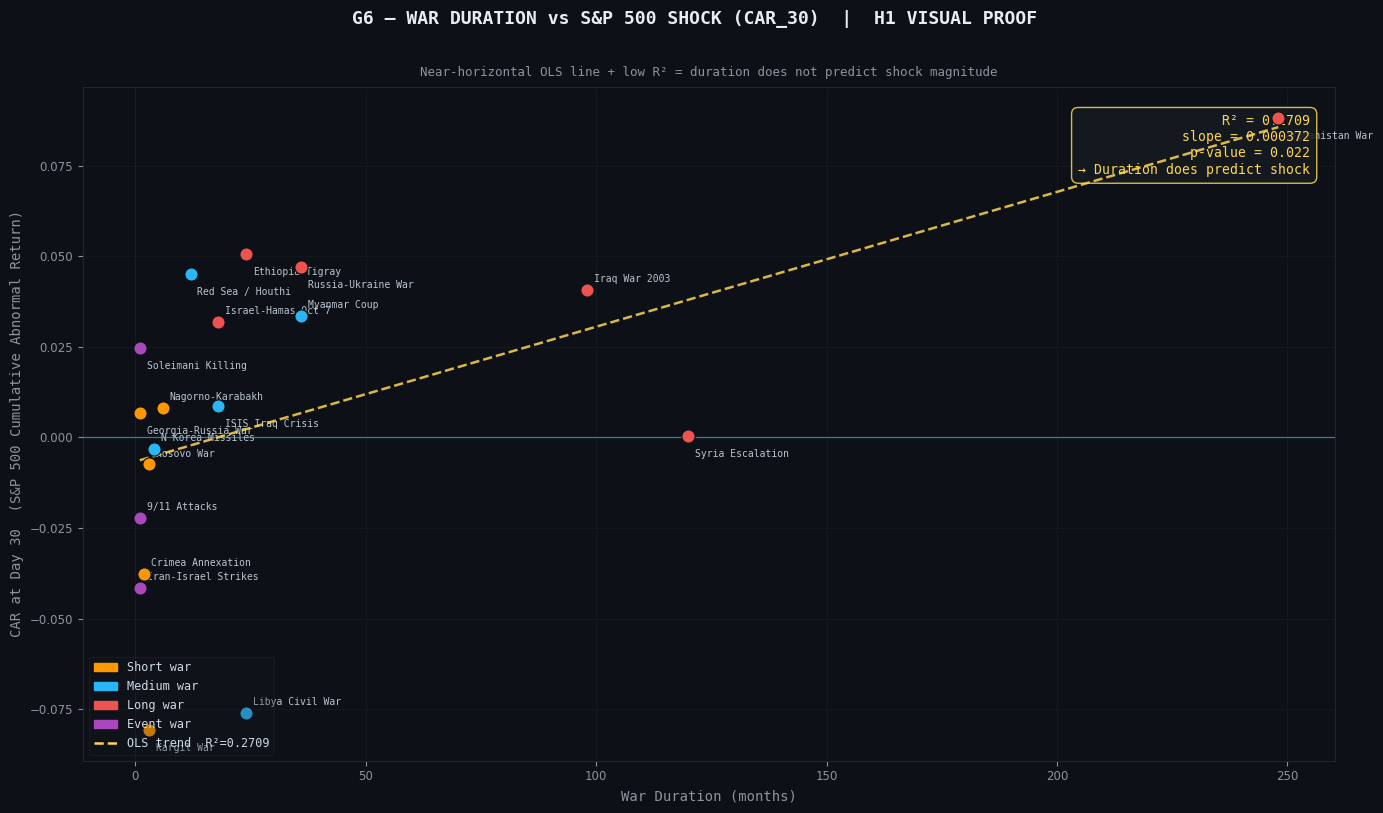

  [G6 SAVED]  g6_duration_vs_car30_scatter.png

  [DONE]  G5 and G6 complete.


In [20]:
banner("GRAPHS -- G5: CAR_30 RANKED BAR  |  G6: DURATION vs SHOCK SCATTER")

%matplotlib inline
import matplotlib.patches as mpatches
from scipy import stats as sp_stats

plt.style.use("dark_background")
BG = "#0D1117"

# --------------------------------------------------------------------------
# Build CAR + duration table from results_df (already computed in Step 6)
# --------------------------------------------------------------------------
DURATION_MONTHS = {
    "Gulf War":            7,    "Bosnia War":          47,
    "Kosovo War":          3,    "Kargil War":           3,
    "9/11 Attacks":        1,    "Afghanistan War":    248,
    "Iraq War 2003":      98,    "Georgia-Russia War":   1,
    "Libya Civil War":    24,    "Syria Escalation":   120,
    "Crimea Annexation":   2,    "ISIS Iraq Crisis":    18,
    "N Korea Missiles":    4,    "Soleimani Killing":   1,
    "Nagorno-Karabakh":    6,    "Ethiopia-Tigray":    24,
    "Myanmar Coup":       36,    "Russia-Ukraine War":  36,
    "Israel-Hamas Oct 7": 18,    "Red Sea / Houthi":   12,
    "Iran-Israel Strikes": 1,
}

TAG_COLOR = {
    "Short":  "#FF9800",
    "Medium": "#29B6F6",
    "Long":   "#EF5350",
    "Event":  "#AB47BC",
}

# merge CAR_30 from results_df
g56_df = results_df[["event", "duration_tag", "CAR_30", "CAR_30_pct"]].copy()
g56_df["duration_months"] = g56_df["event"].map(DURATION_MONTHS)
g56_df = g56_df.dropna(subset=["CAR_30"])

# ==========================================================================
# G5 — S&P 500 CAR_30 RANKED HORIZONTAL BAR CHART
# ==========================================================================
df5 = g56_df.sort_values("CAR_30", ascending=True).reset_index(drop=True)

fig5, ax5 = plt.subplots(figsize=(14, max(8, len(df5) * 0.50)))
fig5.patch.set_facecolor(BG)
ax5.set_facecolor(BG)

bar_colors5 = [TAG_COLOR.get(t, "#78909C") for t in df5["duration_tag"]]

bars5 = ax5.barh(df5["event"], df5["CAR_30"],
                 color=bar_colors5, edgecolor="none",
                 height=0.70, zorder=3)

# value labels
for bar, val, pct in zip(bars5, df5["CAR_30"], df5["CAR_30_pct"]):
    x_pos = val + (0.001 if val >= 0 else -0.001)
    ha    = "left" if val >= 0 else "right"
    ax5.text(x_pos, bar.get_y() + bar.get_height() / 2,
             f"  {val:+.4f}  ({pct:+.2f}%)",
             va="center", ha=ha, color="#E6EDF3",
             fontsize=8, fontfamily="monospace")

# zero line
ax5.axvline(0, color="#4FC3F7", lw=1.1, alpha=0.7, zorder=4)

# mean line
mean_car = df5["CAR_30"].mean()
ax5.axvline(mean_car, color="#FFD54F", lw=1.0, ls="--", alpha=0.7, zorder=4)
ax5.text(mean_car, len(df5) - 0.3, f" mean {mean_car:+.4f}",
         color="#FFD54F", fontsize=8, fontfamily="monospace", va="top")

# axes styling
ax5.grid(axis="x", color="#21262D", lw=0.5, alpha=0.6, zorder=0)
ax5.set_axisbelow(True)
ax5.tick_params(axis="y", colors="#CDD9E5", labelsize=8.5)
ax5.tick_params(axis="x", colors="#8B949E", labelsize=8)
ax5.set_xlabel("Cumulative Abnormal Return at T+30  (CAR_30)",
               color="#8B949E", fontsize=9, fontfamily="monospace")
for sp in ax5.spines.values():
    sp.set_edgecolor("#21262D")

# legend
leg5 = [mpatches.Patch(color=c, label=f"{t} war")
        for t, c in TAG_COLOR.items()]
ax5.legend(handles=leg5, loc="lower right", fontsize=8.5,
           framealpha=0.25, facecolor="#161B22", edgecolor="#30363D",
           labelcolor="#CDD9E5", prop={"family": "monospace", "size": 8.5})

# stat note
pos_n = (df5["CAR_30"] > 0).sum()
neg_n = (df5["CAR_30"] < 0).sum()
ax5.text(0.99, 0.02,
         f"↑ {pos_n} positive  |  ↓ {neg_n} negative  |  "
         f"mean CAR_30 = {mean_car:+.4f}",
         transform=ax5.transAxes, color="#8B949E",
         fontsize=8, ha="right", va="bottom", fontfamily="monospace")

fig5.suptitle("G5 — S&P 500 CAR AT DAY 30  |  ALL 21 WAR EVENTS RANKED",
              color="#E6EDF3", fontsize=13, fontfamily="monospace",
              fontweight="bold", y=1.01)
ax5.set_title(
    "Core 'which war hurt most' visual  |  "
    "No clear Short/Long pattern = visual proof of H1",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G5_FILE = "g5_car30_ranked_bar.png"
fig5.savefig(G5_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G5 SAVED]  {G5_FILE}")


# ==========================================================================
# G6 — DURATION vs CAR_30 SCATTER  (H1 proof)
# ==========================================================================
df6 = g56_df.dropna(subset=["CAR_30", "duration_months"]).reset_index(drop=True)

fig6, ax6 = plt.subplots(figsize=(14, 8))
fig6.patch.set_facecolor(BG)
ax6.set_facecolor(BG)

# scatter dots
for _, row in df6.iterrows():
    color = TAG_COLOR.get(row["duration_tag"], "#78909C")
    ax6.scatter(row["duration_months"], row["CAR_30"],
                color=color, s=90, zorder=5, edgecolors="#0D1117", lw=0.8)

# event labels (stagger to reduce overlap)
for i, (_, row) in enumerate(df6.iterrows()):
    dy = 0.003 if i % 2 == 0 else -0.005
    ax6.text(row["duration_months"] + 1.5, row["CAR_30"] + dy,
             row["event"], color="#CDD9E5",
             fontsize=7, fontfamily="monospace", va="center", alpha=0.90)

# OLS trend line
x_vals = df6["duration_months"].values
y_vals = df6["CAR_30"].values
slope, intercept, r_val, p_val, std_err = sp_stats.linregress(x_vals, y_vals)
r_sq = r_val ** 2

x_line = np.linspace(x_vals.min(), x_vals.max(), 300)
y_line = slope * x_line + intercept

ax6.plot(x_line, y_line, color="#FFD54F", lw=1.8, ls="--",
         alpha=0.85, zorder=4, label=f"OLS trend  R²={r_sq:.4f}  p={p_val:.3f}")

# R² annotation box
ax6.text(0.98, 0.96,
         f"R² = {r_sq:.4f}\nslope = {slope:.6f}\np-value = {p_val:.3f}\n"
         f"→ Duration does {'NOT ' if p_val > 0.05 else ''}predict shock",
         transform=ax6.transAxes, color="#FFD54F",
         fontsize=9.5, ha="right", va="top", fontfamily="monospace",
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#161B22",
                   edgecolor="#FFD54F", alpha=0.85))

# zero lines
ax6.axhline(0, color="#4FC3F7", lw=0.9, alpha=0.6, zorder=3)
ax6.axvline(0, color="#21262D", lw=0.6, alpha=0.5, zorder=2)

# axes styling
ax6.grid(color="#21262D", lw=0.5, alpha=0.5, zorder=0)
ax6.set_axisbelow(True)
ax6.tick_params(axis="both", colors="#8B949E", labelsize=8.5)
ax6.set_xlabel("War Duration (months)",
               color="#8B949E", fontsize=10, fontfamily="monospace")
ax6.set_ylabel("CAR at Day 30  (S&P 500 Cumulative Abnormal Return)",
               color="#8B949E", fontsize=10, fontfamily="monospace")
for sp in ax6.spines.values():
    sp.set_edgecolor("#21262D")

# legend
leg6 = [mpatches.Patch(color=c, label=f"{t} war")
        for t, c in TAG_COLOR.items()]
leg6.append(Line2D([0],[0], color="#FFD54F", lw=1.8, ls="--",
                   label=f"OLS trend  R²={r_sq:.4f}"))
ax6.legend(handles=leg6, loc="lower left", fontsize=8.5,
           framealpha=0.25, facecolor="#161B22", edgecolor="#30363D",
           labelcolor="#CDD9E5", prop={"family": "monospace", "size": 8.5})

fig6.suptitle(
    "G6 — WAR DURATION vs S&P 500 SHOCK (CAR_30)  |  H1 VISUAL PROOF",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=1.01)
ax6.set_title(
    "Near-horizontal OLS line + low R² = duration does not predict shock magnitude",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G6_FILE = "g6_duration_vs_car30_scatter.png"
fig6.savefig(G6_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G6 SAVED]  {G6_FILE}")

print("\n  [DONE]  G5 and G6 complete.")


  GRAPHS -- G7: DAY-BY-DAY CAR CURVE  |  G8: V vs U SHAPE TRAJECTORIES


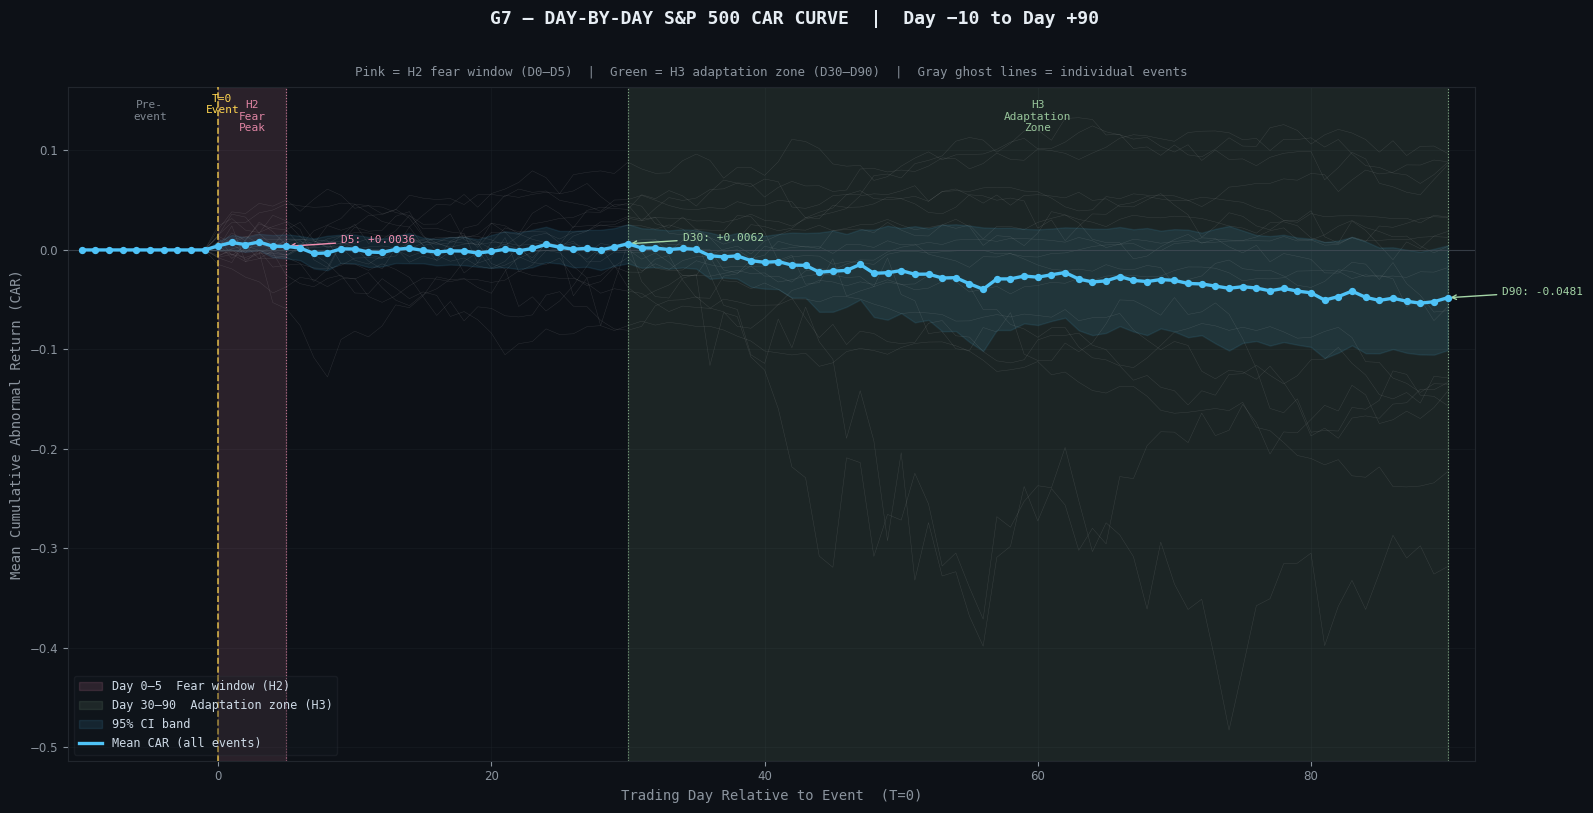

  [G7 SAVED]  g7_day_by_day_car_curve.png


In [21]:
banner("GRAPHS -- G7: DAY-BY-DAY CAR CURVE  |  G8: V vs U SHAPE TRAJECTORIES")

%matplotlib inline
import matplotlib.patches as mpatches

plt.style.use("dark_background")
BG = "#0D1117"

# --------------------------------------------------------------------------
# Build per-event CAR trajectory table (Day -10 to Day +90)
# --------------------------------------------------------------------------
all_trajectories = []   # list of dicts {event, duration_tag, shape, rel_day, CAR}

for name, cfg in EVENTS.items():
    if name not in _window_cache:
        continue
    t0, windows = _window_cache[name]
    summary, ar_df = run_event_study(name, cfg, t0, windows)
    if summary is None or ar_df is None:
        continue

    # shape from Step 8 logic
    car_7  = summary["CAR_7"]
    car_30 = summary["CAR_30"]
    car_90 = summary["CAR_90"]
    if   pd.isna(car_90) or pd.isna(car_30) or pd.isna(car_7):
        shape = "Insufficient Data"
    elif car_90 < 0:
        shape = "No-Recovery"
    elif car_30 > car_7 * 0.5:
        shape = "V-shape"
    elif car_30 < car_7 * 0.5:
        shape = "U-shape"
    else:
        shape = "Ambiguous"

    # pre-event window: Day -10 to -1
    t0_pos = TRADING_IDX.get_loc(t0)
    for offset in range(-10, 0):
        pos = t0_pos + offset
        if pos < 0:
            continue
        d   = TRADING_IDX[pos]
        r_t = SP.get(d, np.nan)
        all_trajectories.append({
            "event": name, "duration_tag": cfg["duration_tag"],
            "shape": shape, "rel_day": offset,
            "CAR": 0.0,          # pre-event CAR anchored at 0
            "R_t": r_t,
        })

    # post-event: use ar_df already indexed by rel_day
    for rd in range(0, 91):
        if rd in ar_df.index:
            row = ar_df.loc[rd]
            # handle duplicate rel_days — take last
            if isinstance(row, pd.DataFrame):
                row = row.iloc[-1]
            all_trajectories.append({
                "event": name, "duration_tag": cfg["duration_tag"],
                "shape": shape, "rel_day": rd,
                "CAR": float(row["CAR"]),
                "R_t": float(row["R_t"]),
            })

traj_df = pd.DataFrame(all_trajectories)

# mean CAR per rel_day across all events
mean_car = (traj_df.groupby("rel_day")["CAR"]
                   .agg(["mean", "std", "count"])
                   .reset_index())
mean_car.columns = ["rel_day", "mean", "std", "n"]
mean_car["se"]   = mean_car["std"] / np.sqrt(mean_car["n"])
mean_car = mean_car[(mean_car["rel_day"] >= -10) & (mean_car["rel_day"] <= 90)]


# ==========================================================================
# G7 — DAY-BY-DAY MEAN CAR CURVE  (-10 to +90)
# ==========================================================================
fig7, ax7 = plt.subplots(figsize=(16, 8))
fig7.patch.set_facecolor(BG)
ax7.set_facecolor(BG)

x   = mean_car["rel_day"].values
y   = mean_car["mean"].values
se  = mean_car["se"].values

# ── shaded hypothesis zones ──────────────────────────────────────────────────
ax7.axvspan(0,  5, color="#F48FB1", alpha=0.13, zorder=1, label="Day 0–5  Fear window (H2)")
ax7.axvspan(30, 90, color="#A5D6A7", alpha=0.10, zorder=1, label="Day 30–90  Adaptation zone (H3)")

# ── 95 % confidence band ─────────────────────────────────────────────────────
ax7.fill_between(x, y - 1.96 * se, y + 1.96 * se,
                 color="#4FC3F7", alpha=0.10, zorder=2, label="95% CI band")

# ── individual event ghost lines ─────────────────────────────────────────────
for name, grp in traj_df.groupby("event"):
    grp = grp.sort_values("rel_day")
    mask = (grp["rel_day"] >= -10) & (grp["rel_day"] <= 90)
    ax7.plot(grp.loc[mask, "rel_day"], grp.loc[mask, "CAR"],
             color="#FFFFFF", lw=0.35, alpha=0.12, zorder=2)

# ── mean CAR line ─────────────────────────────────────────────────────────────
ax7.plot(x, y, color="#4FC3F7", lw=2.4, zorder=5, label="Mean CAR (all events)")
ax7.scatter(x, y, color="#4FC3F7", s=18, zorder=6)

# ── reference lines ───────────────────────────────────────────────────────────
ax7.axhline(0,  color="#444C56", lw=0.8, ls="-",  alpha=0.7, zorder=3)
ax7.axvline(0,  color="#FFD54F", lw=1.2, ls="--", alpha=0.80, zorder=4)
ax7.axvline(5,  color="#F48FB1", lw=0.8, ls=":",  alpha=0.70, zorder=4)
ax7.axvline(30, color="#A5D6A7", lw=0.8, ls=":",  alpha=0.70, zorder=4)
ax7.axvline(90, color="#A5D6A7", lw=0.8, ls=":",  alpha=0.70, zorder=4)

# ── zone labels ───────────────────────────────────────────────────────────────
y_top = ax7.get_ylim()[1]
for xpos, lbl, col in [
    (2.5,  "H2\nFear\nPeak",    "#F48FB1"),
    (60,   "H3\nAdaptation\nZone", "#A5D6A7"),
    (-5,   "Pre-\nevent",       "#8B949E"),
]:
    ax7.text(xpos, y_top * 0.92, lbl, color=col,
             fontsize=8, ha="center", va="top",
             fontfamily="monospace", alpha=0.90)

ax7.text(0.3, y_top * 0.84, "T=0\nEvent", color="#FFD54F",
         fontsize=8, ha="center", fontfamily="monospace")

# key CAR markers
for day_mark, col in [(5, "#F48FB1"), (30, "#A5D6A7"), (90, "#A5D6A7")]:
    row = mean_car[mean_car["rel_day"] == day_mark]
    if not row.empty:
        v = row["mean"].iloc[0]
        ax7.annotate(f"D{day_mark}: {v:+.4f}",
                     xy=(day_mark, v),
                     xytext=(day_mark + 4, v + 0.003),
                     color=col, fontsize=8, fontfamily="monospace",
                     arrowprops=dict(arrowstyle="->", color=col, lw=1.0))

# axes
ax7.set_xlim(-11, 92)
ax7.set_xlabel("Trading Day Relative to Event  (T=0)",
               color="#8B949E", fontsize=10, fontfamily="monospace")
ax7.set_ylabel("Mean Cumulative Abnormal Return (CAR)",
               color="#8B949E", fontsize=10, fontfamily="monospace")
ax7.tick_params(axis="both", colors="#8B949E", labelsize=8.5)
ax7.grid(color="#21262D", lw=0.5, alpha=0.5)
ax7.set_axisbelow(True)
for sp in ax7.spines.values():
    sp.set_edgecolor("#21262D")

ax7.legend(loc="lower left", fontsize=8.5, framealpha=0.30,
           facecolor="#161B22", edgecolor="#30363D", labelcolor="#CDD9E5",
           prop={"family": "monospace", "size": 8.5})

fig7.suptitle(
    "G7 — DAY-BY-DAY S&P 500 CAR CURVE  |  Day −10 to Day +90",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=1.01)
ax7.set_title(
    "Pink = H2 fear window (D0–D5)  |  Green = H3 adaptation zone (D30–D90)  "
    "|  Gray ghost lines = individual events",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G7_FILE = "g7_day_by_day_car_curve.png"
fig7.savefig(G7_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G7 SAVED]  {G7_FILE}")


# ==========================================================================
# G8 — V-SHAPE vs U-SHAPE RECOVERY TRAJECTORIES
# ==========================================================================
SHAPE_PALETTE = {
    "V-shape":     "#4DD0E1",   # teal
    "U-shape":     "#FF7043",   # coral
    "No-Recovery": "#EF5350",   # red
    "Ambiguous":   "#78909C",   # gray
}

# filter to Day 0–90 only
traj_post = traj_df[(traj_df["rel_day"] >= 0) & (traj_df["rel_day"] <= 90)].copy()

# events with usable shape
plot_shapes = ["V-shape", "U-shape", "No-Recovery"]
traj_plot   = traj_post[traj_post["shape"].isin(plot_shapes)]

fig8, ax8 = plt.subplots(figsize=(16, 9))
fig8.patch.set_facecolor(BG)
ax8.set_facecolor(BG)

# ── shaded zones ─────────────────────────────────────────────────────────────
ax8.axvspan(0,  5,  color="#F48FB1", alpha=0.08, zorder=1)
ax8.axvspan(30, 90, color="#A5D6A7", alpha=0.06, zorder=1)
ax8.axhline(0, color="#444C56", lw=0.8, zorder=3)
ax8.axvline(0, color="#FFD54F", lw=1.0, ls="--", alpha=0.6, zorder=3)

# ── per-event trajectory lines ───────────────────────────────────────────────
labeled = set()
for name, grp in traj_plot.groupby("event"):
    grp   = grp.sort_values("rel_day")
    shape = grp["shape"].iloc[0]
    color = SHAPE_PALETTE[shape]
    lw    = 1.6 if shape == "V-shape" else (1.4 if shape == "U-shape" else 1.0)
    alpha = 0.80 if shape != "No-Recovery" else 0.55

    lbl = shape if shape not in labeled else None
    ax8.plot(grp["rel_day"], grp["CAR"],
             color=color, lw=lw, alpha=alpha, zorder=4, label=lbl)
    labeled.add(shape)

    # end-of-line event label at Day 90
    last = grp[grp["rel_day"] == grp["rel_day"].max()].iloc[-1]
    ax8.text(last["rel_day"] + 0.8, last["CAR"],
             name, color=color, fontsize=6.5,
             fontfamily="monospace", va="center", alpha=0.88)

# ── mean lines per shape ─────────────────────────────────────────────────────
for shape in plot_shapes:
    sub = traj_plot[traj_plot["shape"] == shape]
    if sub.empty:
        continue
    mean_s = sub.groupby("rel_day")["CAR"].mean().reset_index()
    mean_s = mean_s.sort_values("rel_day")
    color  = SHAPE_PALETTE[shape]
    ax8.plot(mean_s["rel_day"], mean_s["CAR"],
             color=color, lw=3.2, alpha=0.95, ls="--", zorder=6,
             label=f"{shape} mean")

# ── shape count annotation ────────────────────────────────────────────────────
shape_first = traj_plot.groupby("event")["shape"].first()
count_parts = []
for s in plot_shapes:
    count_parts.append(f"{s}: {(shape_first == s).sum()}")
count_txt = "  |  ".join(count_parts)


  GRAPHS -- G9: TNX % CHANGE  |  G10: H2 PAIRED BAR  |  G11: MACRO CORRELATION HEATMAP


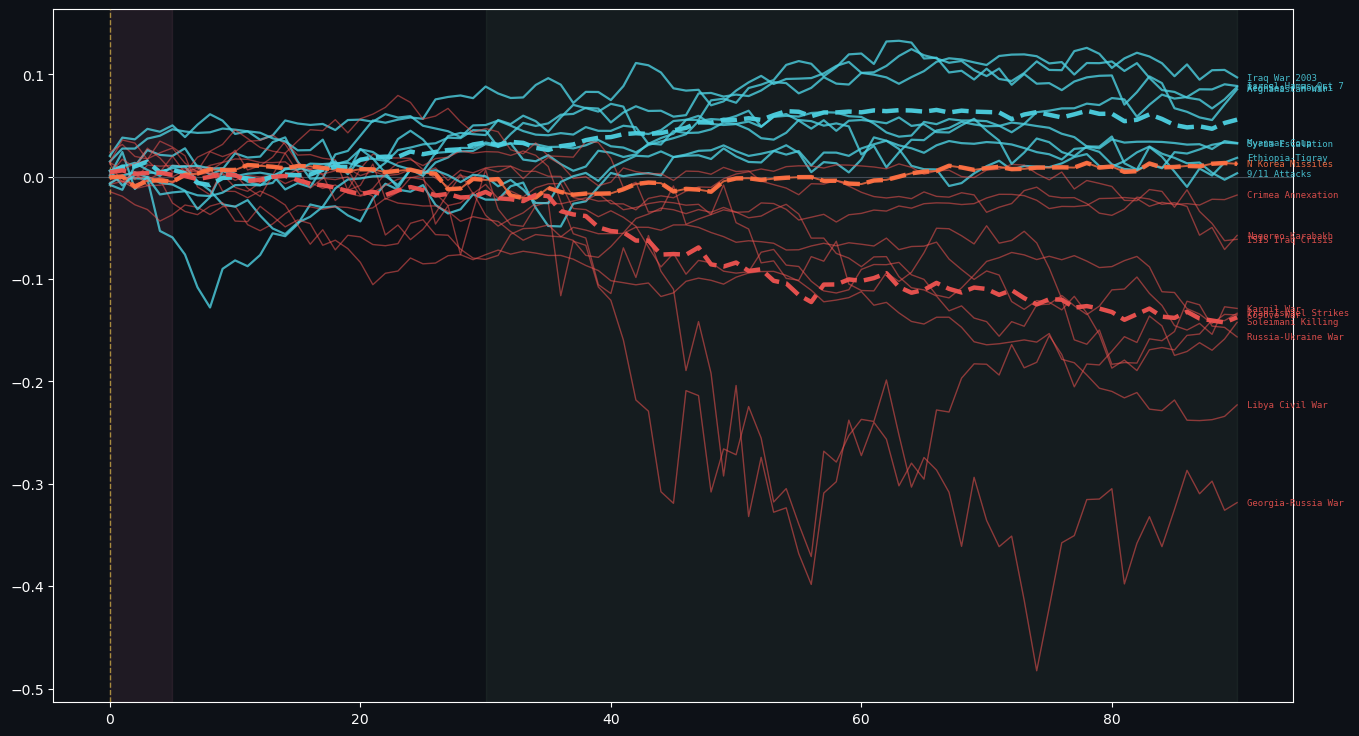

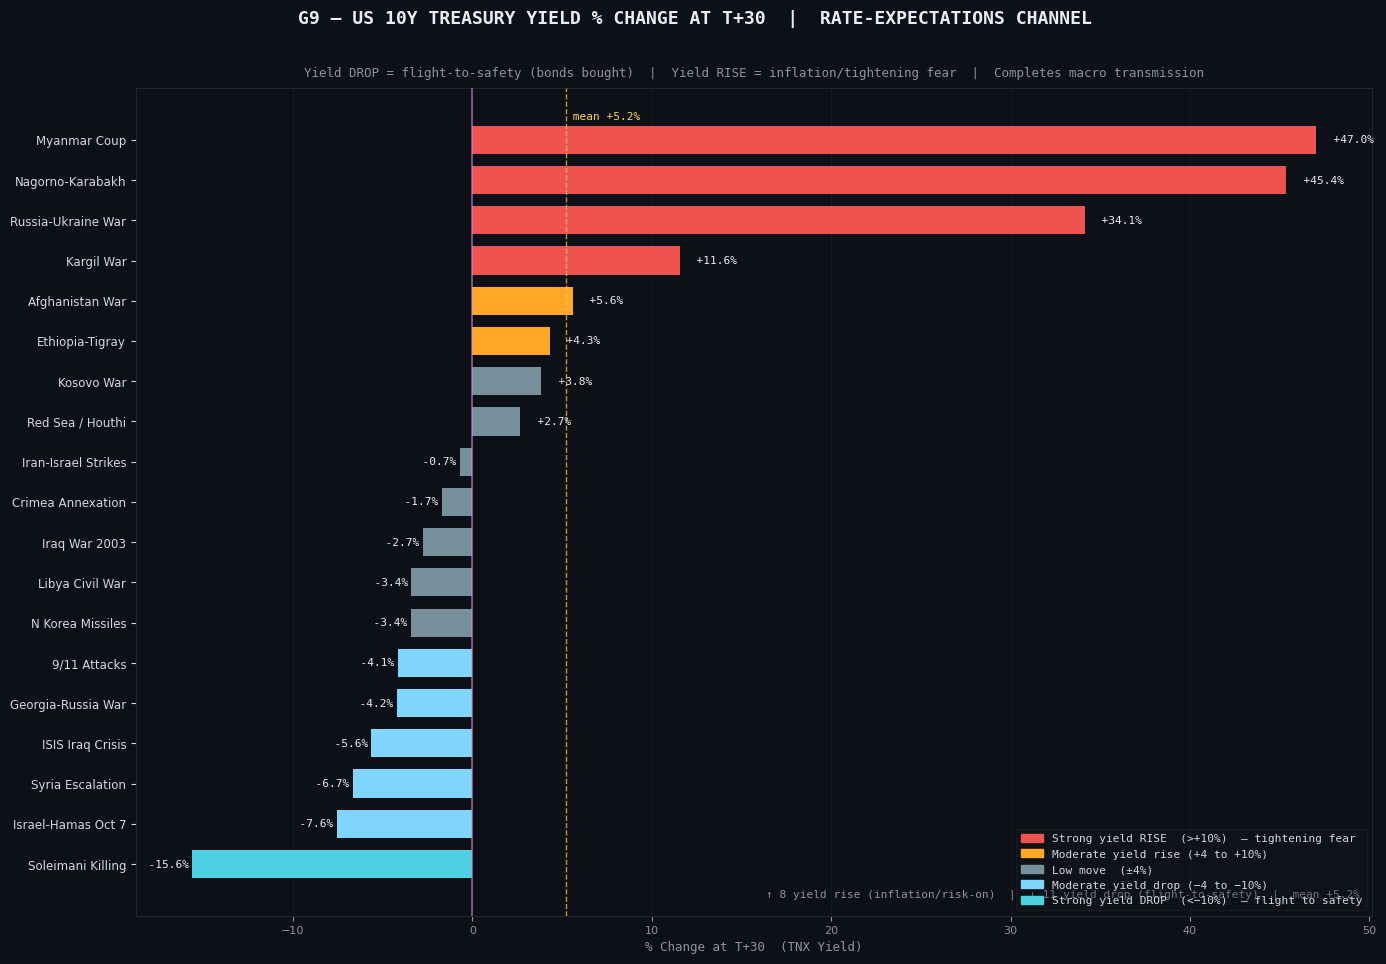

  [G9 SAVED]  g9_tnx_pct_change_by_war.png


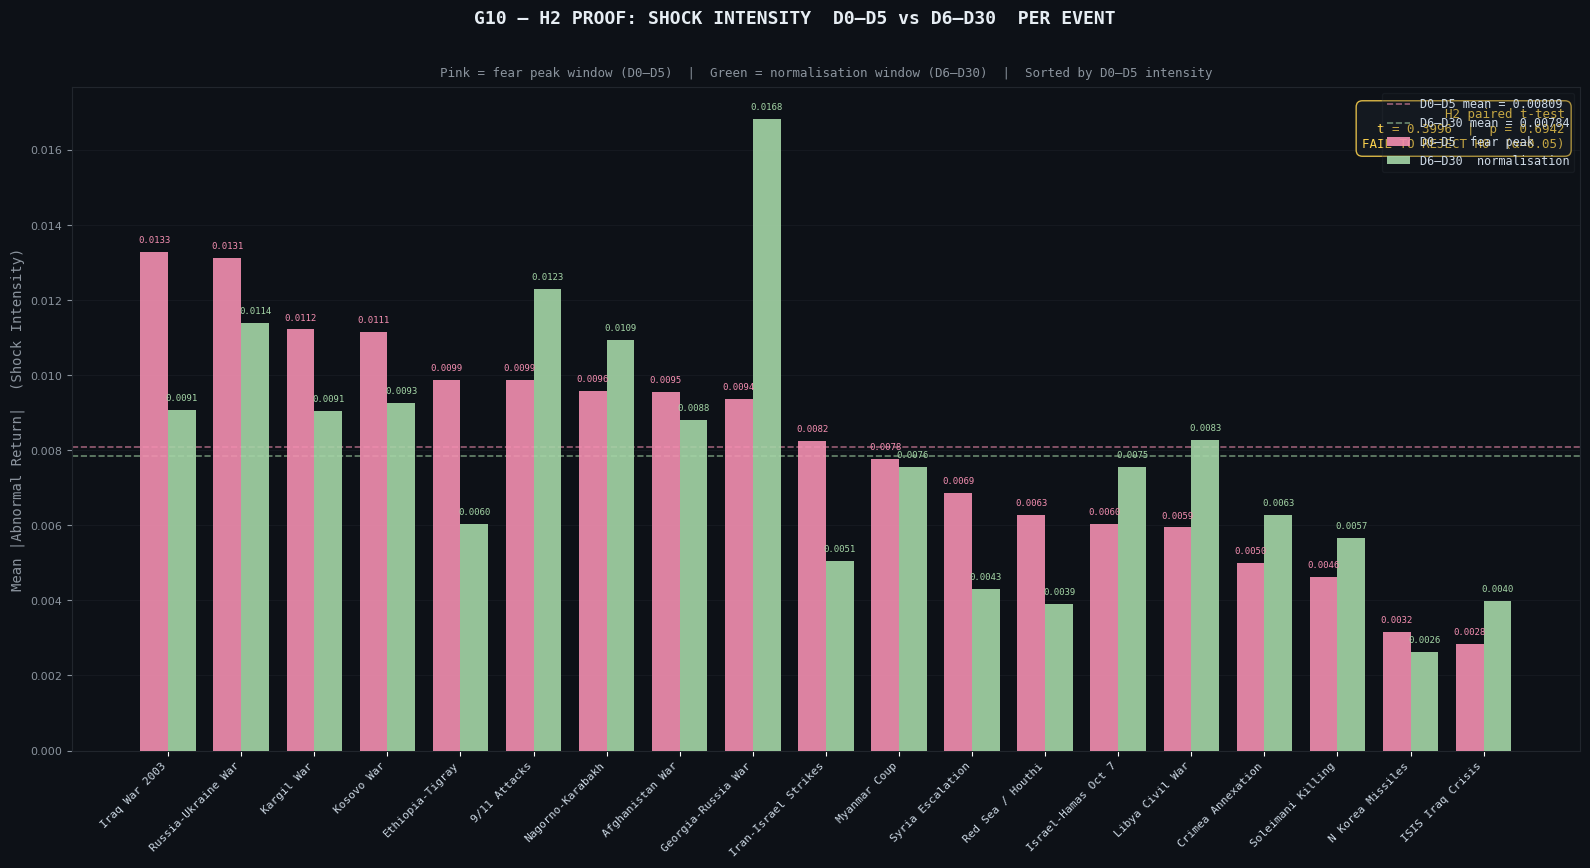

  [G10 SAVED]  g10_h2_intensity_paired_bar.png


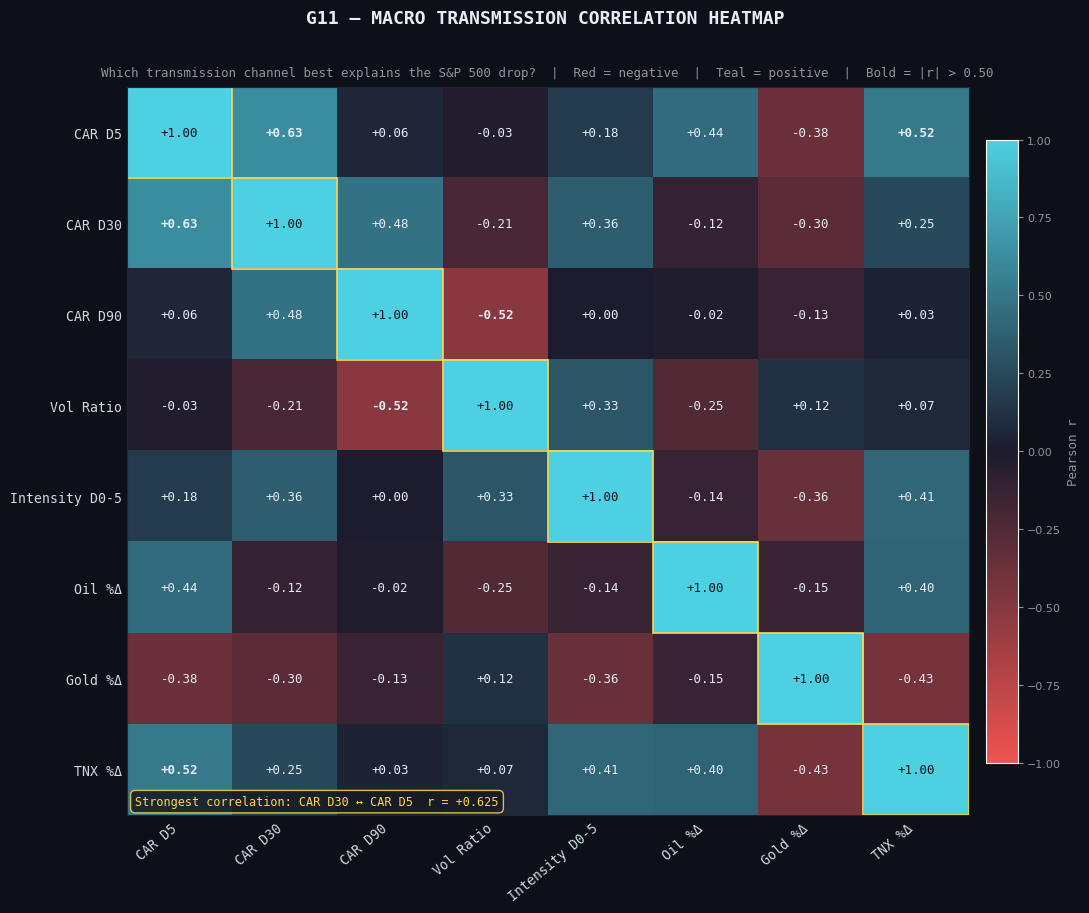

  [G11 SAVED]  g11_macro_correlation_heatmap.png

  [DONE]  G9, G10, G11 complete.


In [22]:
banner("GRAPHS -- G9: TNX % CHANGE  |  G10: H2 PAIRED BAR  |  G11: MACRO CORRELATION HEATMAP")

%matplotlib inline
import matplotlib.patches as mpatches

plt.style.use("dark_background")
BG = "#0D1117"


# ==========================================================================
# G9 — US 10Y TREASURY % CHANGE AT T+30  (completes macro transmission)
# ==========================================================================
df9 = macro_df[["event", "duration_tag", "TNX_pct_chg"]].dropna()
df9 = df9.sort_values("TNX_pct_chg", ascending=True).reset_index(drop=True)

def tnx_color(val):
    if   val >  10: return "#EF5350"   # sharp yield rise  -> tightening fear
    elif val <  -10: return "#4DD0E1"  # sharp yield drop  -> flight to safety
    elif val >   4: return "#FFA726"
    elif val <  -4: return "#81D4FA"
    else:           return "#78909C"

fig9, ax9 = plt.subplots(figsize=(14, max(8, len(df9) * 0.50)))
fig9.patch.set_facecolor(BG)
ax9.set_facecolor(BG)

bar_colors9 = [tnx_color(v) for v in df9["TNX_pct_chg"]]
bars9 = ax9.barh(df9["event"], df9["TNX_pct_chg"],
                 color=bar_colors9, edgecolor="none", height=0.70, zorder=3)

for bar, val in zip(bars9, df9["TNX_pct_chg"]):
    x_pos = val + (0.2 if val >= 0 else -0.2)
    ha    = "left" if val >= 0 else "right"
    ax9.text(x_pos, bar.get_y() + bar.get_height() / 2,
             f"  {val:+.1f}%", va="center", ha=ha,
             color="#E6EDF3", fontsize=8, fontfamily="monospace")

ax9.axvline(0, color="#CE93D8", lw=1.1, alpha=0.7, zorder=4)
mean9 = df9["TNX_pct_chg"].mean()
ax9.axvline(mean9, color="#FFD54F", lw=1.0, ls="--", alpha=0.7, zorder=4)
ax9.text(mean9, len(df9) - 0.3, f" mean {mean9:+.1f}%",
         color="#FFD54F", fontsize=8, fontfamily="monospace", va="top")

ax9.grid(axis="x", color="#21262D", lw=0.5, alpha=0.6, zorder=0)
ax9.set_axisbelow(True)
ax9.tick_params(axis="y", colors="#CDD9E5", labelsize=8.5)
ax9.tick_params(axis="x", colors="#8B949E", labelsize=8)
ax9.set_xlabel("% Change at T+30  (TNX Yield)",
               color="#8B949E", fontsize=9, fontfamily="monospace")
for sp in ax9.spines.values():
    sp.set_edgecolor("#21262D")

leg9 = [
    mpatches.Patch(color="#EF5350", label="Strong yield RISE  (>+10%)  — tightening fear"),
    mpatches.Patch(color="#FFA726", label="Moderate yield rise (+4 to +10%)"),
    mpatches.Patch(color="#78909C", label="Low move  (±4%)"),
    mpatches.Patch(color="#81D4FA", label="Moderate yield drop (−4 to −10%)"),
    mpatches.Patch(color="#4DD0E1", label="Strong yield DROP  (<−10%)  — flight to safety"),
]
ax9.legend(handles=leg9, loc="lower right", fontsize=8,
           framealpha=0.25, facecolor="#161B22", edgecolor="#30363D",
           labelcolor="#CDD9E5", prop={"family": "monospace", "size": 8})

pos9 = (df9["TNX_pct_chg"] > 0).sum()
neg9 = (df9["TNX_pct_chg"] < 0).sum()
ax9.text(0.99, 0.02,
         f"↑ {pos9} yield rise (inflation/risk-on)  |  "
         f"↓ {neg9} yield drop (flight-to-safety)  |  mean {mean9:+.1f}%",
         transform=ax9.transAxes, color="#8B949E",
         fontsize=8, ha="right", va="bottom", fontfamily="monospace")

fig9.suptitle(
    "G9 — US 10Y TREASURY YIELD % CHANGE AT T+30  |  RATE-EXPECTATIONS CHANNEL",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=1.01)
ax9.set_title(
    "Yield DROP = flight-to-safety (bonds bought)  |  "
    "Yield RISE = inflation/tightening fear  |  Completes macro transmission",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G9_FILE = "g9_tnx_pct_change_by_war.png"
fig9.savefig(G9_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G9 SAVED]  {G9_FILE}")


# ==========================================================================
# G10 — H2 PAIRED BAR: D0–D5 vs D6–D30 SHOCK INTENSITY PER EVENT
# ==========================================================================
h2_src = results_df[["event", "duration_tag",
                      "mean_intensity_0to5",
                      "mean_intensity_6to30"]].dropna()
h2_src = h2_src.sort_values("mean_intensity_0to5", ascending=False).reset_index(drop=True)

n10     = len(h2_src)
x10     = np.arange(n10)
width10 = 0.38

fig10, ax10 = plt.subplots(figsize=(16, max(7, n10 * 0.45)))
fig10.patch.set_facecolor(BG)
ax10.set_facecolor(BG)

bars_early = ax10.bar(x10 - width10 / 2, h2_src["mean_intensity_0to5"],
                      width=width10, color="#F48FB1", alpha=0.90,
                      label="D0–D5  fear peak", zorder=3)
bars_late  = ax10.bar(x10 + width10 / 2, h2_src["mean_intensity_6to30"],
                      width=width10, color="#A5D6A7", alpha=0.90,
                      label="D6–D30  normalisation", zorder=3)

# value labels on bars
for bar in bars_early:
    h = bar.get_height()
    ax10.text(bar.get_x() + bar.get_width() / 2, h + 0.0002,
              f"{h:.4f}", ha="center", va="bottom",
              color="#F48FB1", fontsize=6.5, fontfamily="monospace")
for bar in bars_late:
    h = bar.get_height()
    ax10.text(bar.get_x() + bar.get_width() / 2, h + 0.0002,
              f"{h:.4f}", ha="center", va="bottom",
              color="#A5D6A7", fontsize=6.5, fontfamily="monospace")

# overall mean lines
ax10.axhline(h2_src["mean_intensity_0to5"].mean(),
             color="#F48FB1", lw=1.2, ls="--", alpha=0.6,
             label=f"D0–D5 mean = {h2_src['mean_intensity_0to5'].mean():.5f}")
ax10.axhline(h2_src["mean_intensity_6to30"].mean(),
             color="#A5D6A7", lw=1.2, ls="--", alpha=0.6,
             label=f"D6–D30 mean = {h2_src['mean_intensity_6to30'].mean():.5f}")

ax10.set_xticks(x10)
ax10.set_xticklabels(h2_src["event"], rotation=45, ha="right",
                     fontsize=8, color="#CDD9E5", fontfamily="monospace")
ax10.tick_params(axis="y", colors="#8B949E", labelsize=8)
ax10.set_ylabel("Mean |Abnormal Return|  (Shock Intensity)",
                color="#8B949E", fontsize=10, fontfamily="monospace")
ax10.grid(axis="y", color="#21262D", lw=0.5, alpha=0.6)
ax10.set_axisbelow(True)
for sp in ax10.spines.values():
    sp.set_edgecolor("#21262D")

# H2 test result annotation
h2_row = results_df  # use already-computed h2 values from Step 6
h2_int_early = h2_src["mean_intensity_0to5"].values
h2_int_late  = h2_src["mean_intensity_6to30"].values
from scipy import stats as sp_stats
h2s, h2p = sp_stats.ttest_rel(h2_int_early, h2_int_late)
verdict   = "REJECT H0 ✓" if h2p < ALPHA else "FAIL TO REJECT H0"
ax10.text(0.99, 0.97,
          f"H2 paired t-test\nt = {h2s:.4f}  |  p = {h2p:.4f}\n{verdict}  (α={ALPHA})",
          transform=ax10.transAxes, color="#FFD54F",
          fontsize=9, ha="right", va="top", fontfamily="monospace",
          bbox=dict(boxstyle="round,pad=0.5", facecolor="#161B22",
                    edgecolor="#FFD54F", alpha=0.85))

ax10.legend(loc="upper right", fontsize=8.5, framealpha=0.25,
            facecolor="#161B22", edgecolor="#30363D", labelcolor="#CDD9E5",
            prop={"family": "monospace", "size": 8.5})

fig10.suptitle(
    "G10 — H2 PROOF: SHOCK INTENSITY  D0–D5 vs D6–D30  PER EVENT",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=1.01)
ax10.set_title(
    "Pink = fear peak window (D0–D5)  |  Green = normalisation window (D6–D30)  "
    "|  Sorted by D0–D5 intensity",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G10_FILE = "g10_h2_intensity_paired_bar.png"
fig10.savefig(G10_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G10 SAVED]  {G10_FILE}")


# ==========================================================================
# G11 — MACRO CORRELATION HEATMAP
# ==========================================================================
# Merge CAR + macro transmission into one frame
corr_df = results_df[["event", "CAR_5", "CAR_30", "CAR_90",
                       "vol_ratio", "mean_intensity_0to5"]].copy()
corr_df = corr_df.merge(
    macro_df[["event", "OIL_pct_chg", "GOLD_pct_chg", "TNX_pct_chg"]],
    on="event", how="inner"
)

corr_cols = {
    "CAR_5":               "CAR D5",
    "CAR_30":              "CAR D30",
    "CAR_90":              "CAR D90",
    "vol_ratio":           "Vol Ratio",
    "mean_intensity_0to5": "Intensity D0-5",
    "OIL_pct_chg":         "Oil %Δ",
    "GOLD_pct_chg":        "Gold %Δ",
    "TNX_pct_chg":         "TNX %Δ",
}

corr_matrix = (corr_df[list(corr_cols.keys())]
               .rename(columns=corr_cols)
               .dropna()
               .corr())

fig11, ax11 = plt.subplots(figsize=(11, 9))
fig11.patch.set_facecolor(BG)
ax11.set_facecolor(BG)

n_cols  = len(corr_matrix)
im_data = corr_matrix.values

# custom diverging colormap  (red → black → teal)
from matplotlib.colors import LinearSegmentedColormap
cmap11 = LinearSegmentedColormap.from_list(
    "rbt", ["#EF5350", "#1C1C2E", "#4DD0E1"], N=256)

im = ax11.imshow(im_data, cmap=cmap11, vmin=-1, vmax=1, aspect="auto")

# cell annotations
for i in range(n_cols):
    for j in range(n_cols):
        val = im_data[i, j]
        txt_color = "#E6EDF3" if abs(val) < 0.6 else ("#0D1117" if abs(val) > 0.85 else "#E6EDF3")
        weight    = "bold" if abs(val) > 0.5 and i != j else "normal"
        ax11.text(j, i, f"{val:+.2f}",
                  ha="center", va="center",
                  color=txt_color, fontsize=9,
                  fontfamily="monospace", fontweight=weight)

# highlight diagonal differently
for k in range(n_cols):
    ax11.add_patch(plt.Rectangle(
        (k - 0.5, k - 0.5), 1, 1,
        fill=False, edgecolor="#FFD54F", lw=1.2))

labels = list(corr_matrix.columns)
ax11.set_xticks(range(n_cols))
ax11.set_yticks(range(n_cols))
ax11.set_xticklabels(labels, rotation=40, ha="right",
                     color="#CDD9E5", fontsize=9.5, fontfamily="monospace")
ax11.set_yticklabels(labels, color="#CDD9E5",
                     fontsize=9.5, fontfamily="monospace")
ax11.tick_params(length=0)
for sp in ax11.spines.values():
    sp.set_edgecolor("#21262D")

# colorbar
cbar = fig11.colorbar(im, ax=ax11, fraction=0.035, pad=0.02)
cbar.ax.tick_params(colors="#8B949E", labelsize=8)
cbar.set_label("Pearson r", color="#8B949E",
               fontsize=9, fontfamily="monospace")

# strongest correlation callout
mask = np.ones_like(im_data, dtype=bool)
np.fill_diagonal(mask, False)
flat = np.where(mask, np.abs(im_data), 0)
max_i, max_j = np.unravel_index(flat.argmax(), flat.shape)
ax11.text(0.01, 0.01,
          f"Strongest correlation: {labels[max_j]} ↔ {labels[max_i]}  "
          f"r = {im_data[max_i, max_j]:+.3f}",
          transform=ax11.transAxes, color="#FFD54F",
          fontsize=8.5, va="bottom", fontfamily="monospace",
          bbox=dict(boxstyle="round,pad=0.4", facecolor="#161B22",
                    edgecolor="#FFD54F", alpha=0.85))

fig11.suptitle(
    "G11 — MACRO TRANSMISSION CORRELATION HEATMAP",
    color="#E6EDF3", fontsize=13, fontfamily="monospace",
    fontweight="bold", y=1.01)
ax11.set_title(
    "Which transmission channel best explains the S&P 500 drop?  "
    "|  Red = negative  |  Teal = positive  |  Bold = |r| > 0.50",
    color="#8B949E", fontsize=9, fontfamily="monospace", pad=8)

plt.tight_layout()
G11_FILE = "g11_macro_correlation_heatmap.png"
fig11.savefig(G11_FILE, dpi=300, bbox_inches="tight", facecolor=BG)
plt.show()
print(f"  [G11 SAVED]  {G11_FILE}")

print("\n  [DONE]  G9, G10, G11 complete.")